# Trabajo Práctico Integrador
## Diabetes 130-US Hospitals for Years 1999–2008

**Carrera de Especialización en Inteligencia Artificial — FIUBA**  
**Materia:** Análisis de Datos — 4B 2026

**Alumna:** Sofía Diaz

### Problema elegido

Se plantea un problema de clasificación binaria:
Predecir, al momento del alta hospitalaria, si un paciente será readmitido dentro de los 30 días posteriores

La variable original `readmitted` tiene tres categorías (`NO`, `>30`, `<30`). Para este problema se define:

- `readmitted_30 = 1` si `readmitted == "<30"`
- `readmitted_30 = 0` si `readmitted == "NO"` o `readmitted == ">30"`

### Fuente

- UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
- Strack et al. (2014): *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*.

In [34]:
from ucimlrepo import fetch_ucirepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

### 1. Importación del dataset

In [35]:
diabetes_ds = fetch_ucirepo(id=296)

X = diabetes_ds.data.features.copy()
y = diabetes_ds.data.targets.copy()
ids = diabetes_ds.data.ids.copy()

df_raw = pd.concat([ids, X, y], axis=1)

print("Dimensión del dataset completo:", df_raw.shape)
df_raw.head()

C:\Users\54112\anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3357: DtypeWarning: Columns (10) have mixed types.Specify dtype option on import or set low_memory=False.
  if (await self.run_code(code, result,  async_=asy)):


Dimensión del dataset completo: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [36]:
# Descripción de las variables según UCI
diabetes_ds.variables

,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


#### Observación

Cada fila representa un encuentro hospitalario, no necesariamente un paciente diferente. Se comprobará:
- cuántos encuentros hay;
- cuántos pacientes únicos hay;
- cuántos pacientes aparecen más de una vez.

In [37]:
n_encuentros = len(df_raw)
n_pacientes = df_raw["patient_nbr"].nunique()

encuentros_por_paciente = df_raw["patient_nbr"].value_counts()

print(f"Encuentros hospitalarios: {n_encuentros:,}")
print(f"Pacientes únicos:        {n_pacientes:,}")
print(f"Pacientes con 1 encuentro: {(encuentros_por_paciente == 1).sum():,}")
print(f"Pacientes con >1 encuentro: {(encuentros_por_paciente > 1).sum():,}")
print(f"Máximo de encuentros de un mismo paciente: {encuentros_por_paciente.max()}")

Encuentros hospitalarios: 101,766
Pacientes únicos:        71,518
Pacientes con 1 encuentro: 54,745
Pacientes con >1 encuentro: 16,773
Máximo de encuentros de un mismo paciente: 40


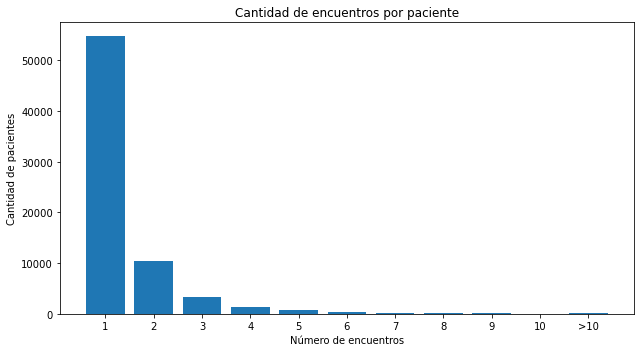

In [38]:
# Distribución de cantidad de encuentros por paciente
freq_encuentros = encuentros_por_paciente.value_counts().sort_index()

# Mostramos 1 a 10 y agrupamos el resto para que el gráfico sea legible
plot_enc = freq_encuentros.loc[freq_encuentros.index <= 10].copy()
mas_10 = freq_encuentros.loc[freq_encuentros.index > 10].sum()

if mas_10 > 0:
    plot_enc.loc[11] = mas_10

labels = [str(i) if i <= 10 else ">10" for i in plot_enc.index]

plt.figure(figsize=(9, 5))
plt.bar(labels, plot_enc.values)
plt.title("Cantidad de encuentros por paciente")
plt.xlabel("Número de encuentros")
plt.ylabel("Cantidad de pacientes")
plt.tight_layout()
plt.show()

In [39]:
# Metadata
print(diabetes_ds.metadata)

{'uci_id': 296, 'name': 'Diabetes 130-US Hospitals for Years 1999-2008', 'repository_url': 'https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008', 'data_url': 'https://archive.ics.uci.edu/static/public/296/data.csv', 'abstract': 'The dataset represents ten years (1999-2008) of clinical care at 130 US hospitals and integrated delivery networks. Each row concerns hospital records of patients diagnosed with diabetes, who underwent laboratory, medications, and stayed up to 14 days. The goal is to determine the early readmission of the patient within 30 days of discharge.\nThe problem is important for the following reasons. Despite high-quality evidence showing improved clinical outcomes for diabetic patients who receive various preventive and therapeutic interventions, many patients do not receive them. This can be partially attributed to arbitrary diabetes management in hospital environments, which fail to attend to glycemic control. Failure to provide pro

#### Descripción del dataset según metadatos

El dataset contiene información de 101.766 encuentros hospitalarios de pacientes con diagnóstico de diabetes, registrados durante 10 años (1999–2008) en 130 hospitales de Estados Unidos. Incluye 47 variables predictoras de tipo categórico y entero, además de la variable objetivo `readmitted`.

Los registros corresponden a internaciones de entre 1 y 14 días en las que se realizaron estudios de laboratorio y se administraron medicamentos. Entre las variables se incluyen edad, género, raza, tipo de admisión, duración de la internación, diagnósticos, estudios de laboratorio, medicación y antecedentes de consultas e internaciones previas.

La variable `readmitted` indica si el paciente fue readmitido antes de 30 días (`<30`), después de 30 días (`>30`) o no fue readmitido (`NO`).

##### Observaciones iniciales
- Cada fila representa un encuentro hospitalario, no necesariamente un paciente único. Los identificadores `encounter_id` y `patient_nbr` se encuentran separados de las features.
- El dataset contiene valores faltantes (`NaN`) en algunas variables.
- En variables como `A1Cresult` y `max_glu_serum` aparece la categoría `"None"`, que no representa un NaN, sino que indica que el estudio no fue realizado.

### 2. Análisis exploratorio

In [40]:
print(f"Número de observaciones: {df_raw.shape[0]:,}")
print(f"Número de variables: {df_raw.shape[1]}")
print(f"Features: {X.shape[1]}")
print(f"Target: {y.columns.tolist()}")

Número de observaciones: 101,766
Número de variables: 50
Features: 47
Target: ['readmitted']


In [41]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

#### 2.1 Variables

In [42]:
variables_numericas_raw = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

ids_cols = ["encounter_id", "patient_nbr"]

variables_categoricas_raw = [
    col for col in X.columns
    if col not in variables_numericas_raw
]

print("IDs:", len(ids_cols))
print("Variables numéricas conceptuales:", len(variables_numericas_raw))
print("Variables categóricas predictoras:", len(variables_categoricas_raw))
print("Target categórico original: readmitted")

IDs: 2
Variables numéricas conceptuales: 8
Variables categóricas predictoras: 39
Target categórico original: readmitted


##### 2.1.1 Variables numéricas

In [43]:
resumen_numericas = df_raw[variables_numericas_raw].describe().T

resumen_numericas["mediana"] = df_raw[variables_numericas_raw].median()
resumen_numericas["varianza"] = df_raw[variables_numericas_raw].var()

resumen_numericas["IQR"] = (
    df_raw[variables_numericas_raw].quantile(0.75)
    - df_raw[variables_numericas_raw].quantile(0.25)
)

resumen_numericas[
    ["count","mean","mediana","std","varianza","min","25%","50%","75%","max","IQR"]].round(2)

,count,mean,mediana,std,varianza,min,25%,50%,75%,max,IQR
time_in_hospital,101766.0,4.40,4.0,2.99,8.91,1.0,2.0,4.0,6.0,14.0,4.0
num_lab_procedures,101766.0,43.10,44.0,19.67,387.08,1.0,31.0,44.0,57.0,132.0,26.0
num_procedures,101766.0,1.34,1.0,1.71,2.91,0.0,0.0,1.0,2.0,6.0,2.0
num_medications,101766.0,16.02,15.0,8.13,66.06,1.0,10.0,15.0,20.0,81.0,10.0
number_outpatient,101766.0,0.37,0.0,1.27,1.61,0.0,0.0,0.0,0.0,42.0,0.0
number_emergency,101766.0,0.20,0.0,0.93,0.87,0.0,0.0,0.0,0.0,76.0,0.0
number_inpatient,101766.0,0.64,0.0,1.26,1.59,0.0,0.0,0.0,1.0,21.0,1.0
number_diagnoses,101766.0,7.42,8.0,1.93,3.74,1.0,6.0,8.0,9.0,16.0,3.0


##### 2.1.2 Variables categóricas

In [44]:
def resumen_categorica(s):
    vc = s.value_counts(dropna=False)

    return pd.Series({
        "cardinalidad": s.nunique(dropna=True),
        "moda": vc.index[0],
        "proporcion_moda_%": vc.iloc[0] / len(s) * 100, ## qué tan concentrada está la variable en una sola categoría
        "faltantes_%": s.isna().mean() * 100
    })


resumen_categoricas = (
    df_raw[variables_categoricas_raw + ["readmitted"]]
    .apply(resumen_categorica)
    .T
    .sort_values("cardinalidad", ascending=False)
)

resumen_categoricas

,cardinalidad,moda,proporcion_moda_%,faltantes_%
diag_3,789,250,11.35448,1.398306
diag_2,748,276,6.634829,0.351787
diag_1,716,428,6.74292,0.020636
medical_specialty,72.0,NaN,49.082208,49.082208
discharge_disposition_id,26.0,1.0,59.188727,0.0
admission_source_id,17.0,7.0,56.496276,0.0
payer_code,17.0,NaN,39.557416,39.557416
age,10,[70-80),25.615628,0.0
weight,9.0,NaN,96.858479,96.858479
admission_type_id,8.0,1.0,53.053083,0.0


#### Observaciones generales

- El dataset contiene 101.766 encuentros correspondientes a 71.518 pacientes únicos, por lo que existen pacientes con múltiples internaciones.
- Se identificaron 8 variables numéricas y 39 variables categóricas predictoras, además de la variable target `readmitted`.
- Algunas variables categóricas presentan alta cardinalidad, especialmente `diag_1`, `diag_2` y `diag_3`.
- Se observan variables con una proporción elevada de valores faltantes, particularmente `weight`, `medical_specialty` y `payer_code`. Su análisis detallado se realizará más adelante.

### 3. Patrones generales y distribuciones

#### 3.1 Distribución de variable objetivo

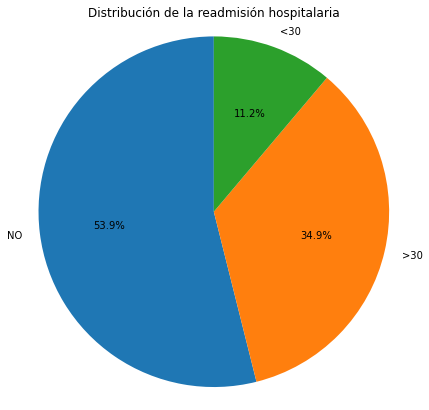

In [45]:
readm_counts = df_raw["readmitted"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    readm_counts,
    labels=readm_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de la readmisión hospitalaria")
plt.axis("equal")
plt.show()

Interpretación: en el dataset crudo, aproximadamente 53,9 % de los encuentros no registran readmisión, 34,9 % presentan readmisión después de 30 días y sólo 11,2 % corresponden a readmisión temprana. Por lo tanto, la clase <30, que es justamente la de interés para el problema planteado, es claramente minoritaria y existe **desbalance** de clases.

#### 3.2 Distribución por rango etario

age es una variable categórica ordinal expresada en intervalos de diez años.

Interpretación esperada según análisis anterior: la población está concentrada principalmente en adultos mayores. El rango [70–80) es el más representado, seguido por [60–70) y [80–90). Esto muestra que las internaciones diabéticas del dataset corresponden mayoritariamente a pacientes de edad avanzada.

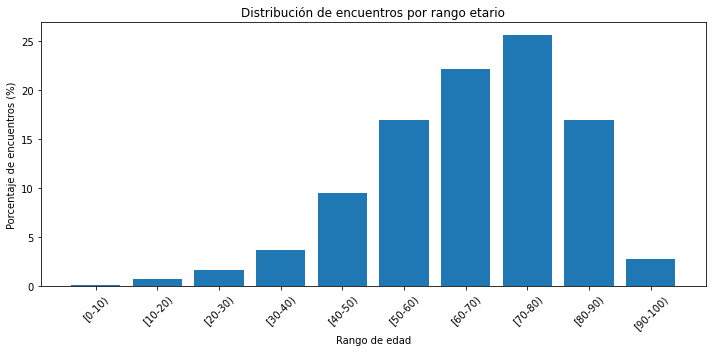

[0-10)       0.16
[10-20)      0.68
[20-30)      1.63
[30-40)      3.71
[40-50)      9.52
[50-60)     16.96
[60-70)     22.09
[70-80)     25.62
[80-90)     16.90
[90-100)     2.74
Name: age, dtype: float64

In [46]:
age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
    "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"
]

age_pct = (df_raw["age"].value_counts(normalize=True).reindex(age_order).dropna()* 100)

plt.figure(figsize=(10, 5))
plt.bar(age_pct.index, age_pct.values)
plt.title("Distribución de encuentros por rango etario")
plt.xlabel("Rango de edad")
plt.ylabel("Porcentaje de encuentros (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

age_pct.round(2)

#### 3.3 Duración de internaciones

time_in_hospital es una variable cuantitativa discreta entre 1 y 14 días.

Interpretación esperada: predominan las internaciones relativamente cortas, especialmente de aproximadamente 2 a 4 días, y la frecuencia disminuye a medida que aumenta la duración de la estadía. La distribución presenta una cola hacia internaciones más prolongadas.

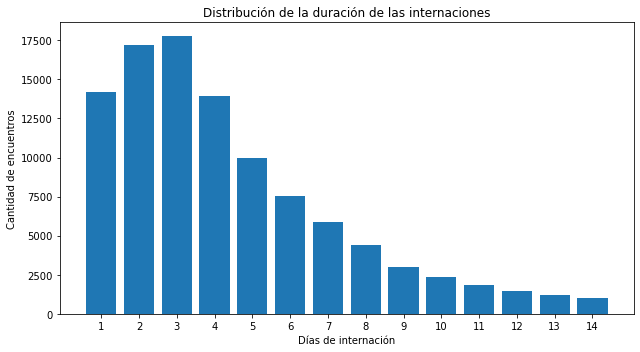

In [47]:
los_counts = df_raw["time_in_hospital"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(los_counts.index.astype(str), los_counts.values)
plt.title("Distribución de la duración de las internaciones")
plt.xlabel("Días de internación")
plt.ylabel("Cantidad de encuentros")
plt.tight_layout()
plt.show()

#### 3.4 Distribución de variables numéricas

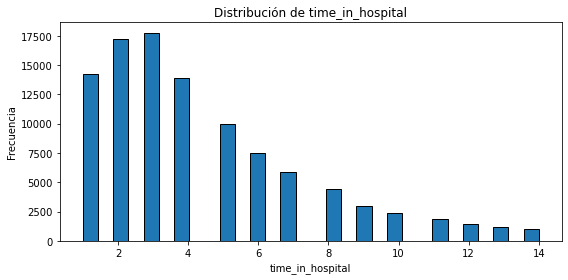

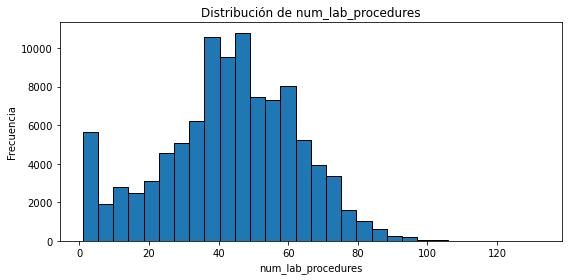

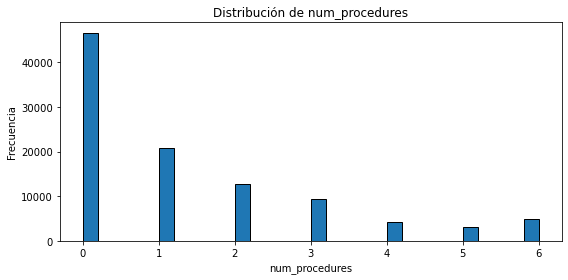

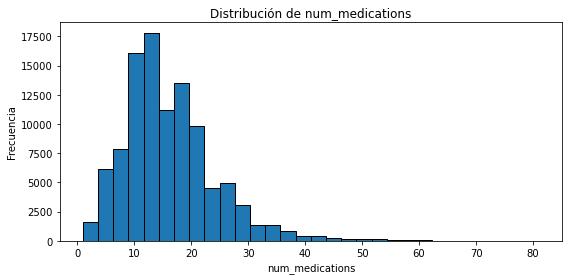

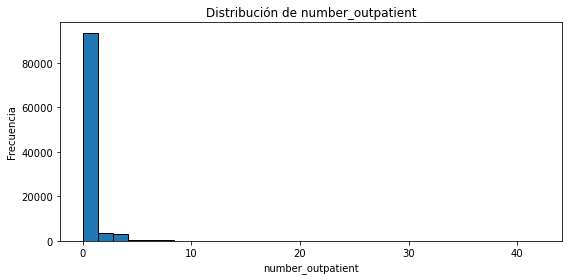

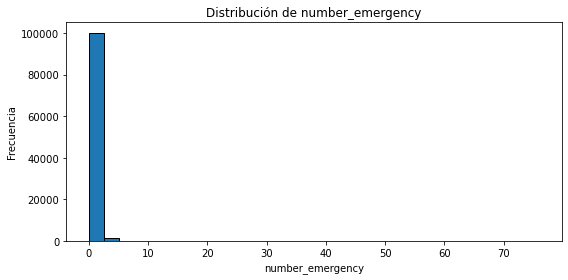

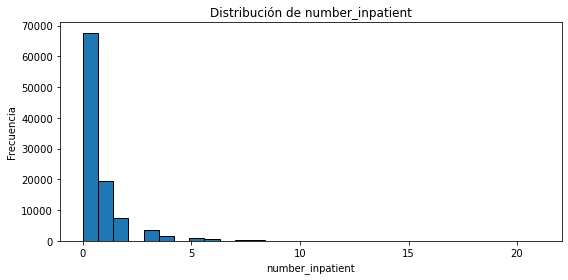

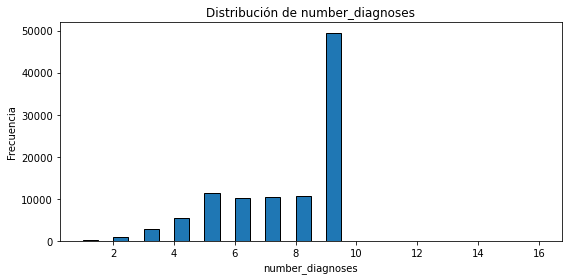

In [48]:
for col in variables_numericas_raw:
    plt.figure(figsize=(8, 4))
    plt.hist(df_raw[col].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

Interpretación: Las variables numéricas presentan distribuciones diferentes. `time_in_hospital`, `num_procedures` y `num_medications` muestran una mayor concentración en valores bajos o intermedios y cierta asimetría hacia valores altos. Las variables `number_outpatient`, `number_emergency` y `number_inpatient` presentan una marcada concentración en cero y una cola hacia la derecha, indicando que la mayoría de los pacientes tuvo pocas o ninguna consulta o internación previa, mientras que unos pocos presentan valores elevados. `number_diagnoses` se concentra principalmente entre 5 y 9 diagnósticos.

#### 3.5 Readmisión según rango etario


Se analiza la proporción de cada categoría de `readmitted` dentro de los distintos rangos de edad.

Como `age` es una variable categórica ordinal, se utiliza una tabla de contingencia normalizada por fila. De esta forma, cada rango etario suma 100% y permite comparar cómo se distribuye la readmisión entre grupos de edad, independientemente de cuántos pacientes haya en cada grupo.

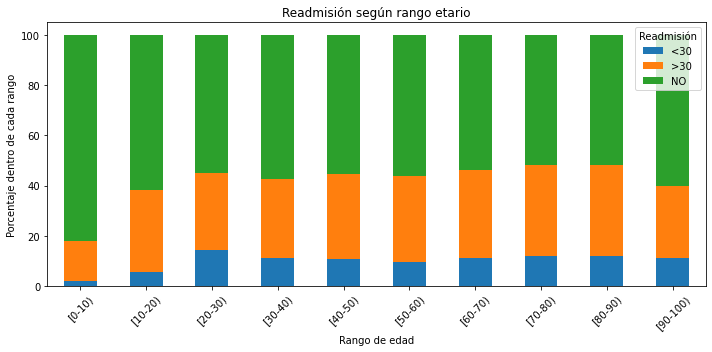

readmitted,<30,>30,NO
age,,,
[0-10),1.86,16.15,81.99
[10-20),5.79,32.42,61.79
[20-30),14.24,30.78,54.98
[30-40),11.23,31.44,57.32
[40-50),10.60,33.85,55.55
[50-60),9.67,34.29,56.04
[60-70),11.13,35.12,53.75
[70-80),11.77,36.35,51.88
[80-90),12.08,36.19,51.73


In [49]:
tabla_edad_readmision = pd.crosstab(df_raw["age"], df_raw["readmitted"], normalize="index") * 100

tabla_edad_readmision.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Readmisión según rango etario")
plt.xlabel("Rango de edad")
plt.ylabel("Porcentaje dentro de cada rango")
plt.legend(title="Readmisión")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

tabla_edad_readmision.round(2)

Interpretación: Se observa una tendencia general a un mayor porcentaje de readmisión en los grupos de mayor edad. 
En los pacientes más jóvenes predomina ampliamente la categoría `NO`, mientras que a medida que aumenta la edad crece la proporción de readmisiones, tanto antes como después de los 30 días. La categoría `<30` muestra un aumento especialmente visible en los rangos etarios más avanzados.
(El grupo de 90 a 100 años presenta un comportamiento diferente, por lo que habría que considerar la cantidad de observaciones de ese rango antes de interpretar esta diferencia)

#### 3.6 Duración de la internación según readmisión 

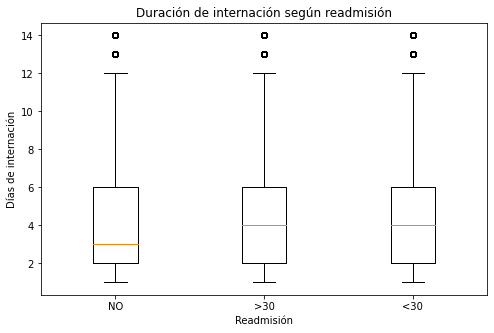

In [50]:
orden_readmision = ["NO", ">30", "<30"]
datos_boxplot = [df_raw.loc[df_raw["readmitted"] == categoria, "time_in_hospital"].dropna() for categoria in orden_readmision]

plt.figure(figsize=(8, 5))
plt.boxplot(datos_boxplot, labels=orden_readmision)
plt.title("Duración de internación según readmisión")
plt.xlabel("Readmisión")
plt.ylabel("Días de internación")
plt.show()

Interpretación: Las distribuciones de la duración de la internación son similares entre las tres categorías de readmisión. Como una primera observación, visualmente `time_in_hospital` por sí sola no parece discriminar fuertemente entre las categorías de readmisión.

### 4. Medición de asociación entre variables

**Definición del target binario**

Como el objetivo del trabajo es analizar la readmisión temprana, se crea una variable binaria:

- `1`: readmisión antes de 30 días (`<30`)
- `0`: no readmisión temprana (`NO` o `>30`)

In [51]:
df_raw["readmitted_30"] = (df_raw["readmitted"] == "<30").astype(int)

In [52]:
df_raw["readmitted_30"] = (df_raw["readmitted"] == "<30").astype(int)

df_raw["readmitted_30"].value_counts(normalize=True).mul(100).round(2)

0    88.84
1    11.16
Name: readmitted_30, dtype: float64

Se utilizarán las herramientas de medición de asociación acordes, teniendo en cuenta que la naturaleza de las variables:

**Variables numéricas**

Variables cuantitativas discretas:

- `time_in_hospital`
- `num_lab_procedures`
- `num_procedures`
- `num_medications`
- `number_outpatient`
- `number_emergency`
- `number_inpatient`
- `number_diagnoses`

**Variables categóricas ordinales**

- `age`: rangos etarios ordenados.
- `weight`: intervalos de peso ordenados. 

**Variables categóricas binarias**

- `change`: indica si hubo cambio en la medicación.
- `diabetesMed`: indica si se prescribió medicación para diabetes.
- `readmitted_30`: target generado para el problema de clasificación:
  - `1`: readmisión antes de 30 días.
  - `0`: no readmisión temprana.

**Variables categóricas nominales**

- `race`
- `gender`
- `admission_type_id`
- `discharge_disposition_id`
- `admission_source_id`
- `payer_code`
- `medical_specialty`
- `diag_1`
- `diag_2`
- `diag_3`
- `max_glu_serum`
- `A1Cresult`
- `metformin`
- `repaglinide`
- `nateglinide`
- `chlorpropamide`
- `glimepiride`
- `acetohexamide`
- `glipizide`
- `glyburide`
- `tolbutamide`
- `pioglitazone`
- `rosiglitazone`
- `acarbose`
- `miglitol`
- `troglitazone`
- `tolazamide`
- `examide`
- `citoglipton`
- `insulin`
- `glyburide-metformin`
- `glipizide-metformin`
- `glimepiride-pioglitazone`
- `metformin-rosiglitazone`
- `metformin-pioglitazone`
- `readmitted` (variable original con las categorías `NO`, `>30` y `<30`).

En particular, `admission_type_id`, `discharge_disposition_id` y `admission_source_id` están almacenadas como números, pero representan códigos de categorías y por lo tanto se consideran variables categóricas nominales.


#### 4.1 Asociación entre variables numéricas

Para analizar la relación entre las variables numéricas se utiliza la **correlación de Spearman**.

Se elige Spearman en lugar de Pearson porque varias de las variables son conteos discretos, presentan distribuciones asimétricas y posibles valores extremos.

Los valores del coeficiente varían entre -1 y 1:
- valores cercanos a 1 indican una asociación positiva fuerte;
- valores cercanos a -1 indican una asociación negativa fuerte;
- valores cercanos a 0 indican poca o ninguna asociación.

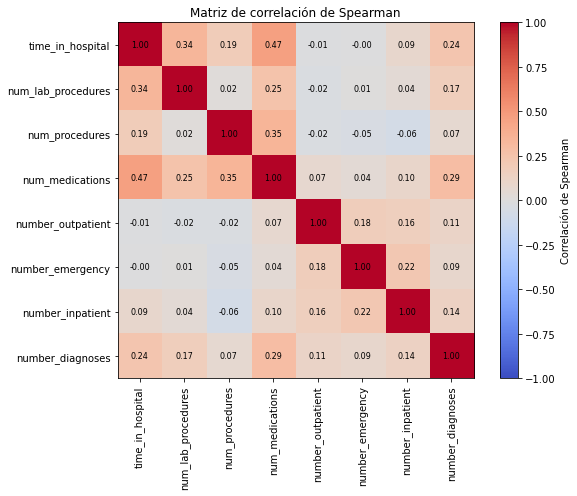

In [53]:
corr_spearman = df_raw[variables_numericas_raw].corr(method="spearman")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr_spearman, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(im, label="Correlación de Spearman")
plt.xticks(range(len(variables_numericas_raw)), variables_numericas_raw, rotation=90)
plt.yticks(range(len(variables_numericas_raw)), variables_numericas_raw)

for i in range(len(variables_numericas_raw)):
    for j in range(len(variables_numericas_raw)):
        plt.text(j, i, f"{corr_spearman.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

Interpretación: En general, no se observan correlaciones fuertes entre las variables numéricas. La asociación más elevada aparece entre `time_in_hospital` y `num_medications` (0,47), indicando que las internaciones más prolongadas tienden a estar asociadas con una mayor cantidad de medicamentos, lo que tiene sentido en la vida real. También se observan asociaciones positivas moderadas entre `num_procedures` y `num_medications` (0,35), y entre `time_in_hospital` y `num_lab_procedures` (0,34). El resto de las asociaciones son débiles, por lo que no se observa una redundancia importante entre las variables numéricas.

#### 4.2 Asociación entre variables numéricas y el target

Para analizar la relación entre las variables numéricas y el target binario `readmitted_30` se utiliza la **correlación punto-biserial**.

In [54]:
from scipy.stats import pointbiserialr

resultados_pb = []

for col in variables_numericas_raw:
    datos = df_raw[[col, "readmitted_30"]].dropna()
    r, p = pointbiserialr(datos["readmitted_30"], datos[col])
    resultados_pb.append([col, r, p])

df_pb = pd.DataFrame(resultados_pb, columns=["variable", "punto_biserial", "p_value"]).sort_values("punto_biserial", key=abs, ascending=False)
df_pb

,variable,punto_biserial,p_value
6,number_inpatient,0.165147,0.000000e+00
5,number_emergency,0.060747,8.295437e-84
7,number_diagnoses,0.049524,2.735181e-56
0,time_in_hospital,0.044199,3.454568e-45
3,num_medications,0.038432,1.405939e-34
1,num_lab_procedures,0.020364,8.207771e-11
4,number_outpatient,0.018893,1.663825e-09
2,num_procedures,-0.012227,9.596024e-05


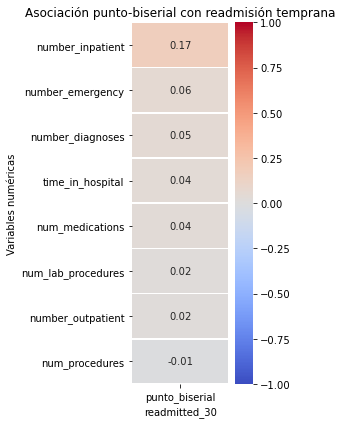

In [55]:
import seaborn as sns

plt.figure(figsize=(4, 6))
sns.heatmap(df_pb.set_index("variable")[["punto_biserial"]], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Asociación punto-biserial con readmisión temprana")
plt.xlabel("readmitted_30")
plt.ylabel("Variables numéricas")
plt.tight_layout()
plt.show()

Interpretación: En general, las variables numéricas presentan una asociación débil con la readmisión temprana.
La variable con mayor asociación es `number_inpatient` (r ≈ 0,17), pero ninguna de las variables numéricas analizadas presenta por sí sola una asociación fuerte con la readmisión temprana.

#### 4.3 Asociación entre variables categóricas ordinales y el target

Para evaluar la asociación entre las variables categóricas ordinales y el target binario `readmitted_30` se utiliza el coeficiente **Kendall Tau**.

In [56]:
from scipy.stats import kendalltau

age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
weight_order = ["[0-25)", "[25-50)", "[50-75)", "[75-100)", "[100-125)", "[125-150)", "[150-175)", "[175-200)", ">200"]

ordenes = {"age": age_order, "weight": weight_order}
resultados_kendall = []

for col, orden in ordenes.items():
    ordinal = df_raw[col].map({categoria: i for i, categoria in enumerate(orden)})
    datos = pd.DataFrame({"ordinal": ordinal, "readmitted_30": df_raw["readmitted_30"]}).dropna()
    tau, p = kendalltau(datos["ordinal"], datos["readmitted_30"])
    resultados_kendall.append([col, tau, p, len(datos)])

df_kendall = pd.DataFrame(resultados_kendall, columns=["variable", "kendall_tau", "p_value", "n"])
df_kendall

,variable,kendall_tau,p_value,n
0,age,0.017270,5.030206e-10,101766
1,weight,-0.016636,3.072425e-01,3197


Interpretación: `age` presenta una asociación positiva muy débil con la readmisión temprana (τ ≈ 0,017).
En `weight` la asociación también es prácticamente nula (τ ≈ -0,017) y no resulta estadísticamente significativa (p ≈ 0,31). Además, este análisis se basa en solo 3.197 registros debido a la gran cantidad de valores faltantes.

#### 4.4 Asociación entre variables categóricas nominales y el target

Para evaluar la asociación entre las variables categóricas nominales y el target binario `readmitted_30` se utiliza **Cramer's V**.

In [57]:
ordinal_cols = ["age", "weight"]
binary_cols = ["change", "diabetesMed"]

nominal_cols = [col for col in variables_categoricas_raw if col not in ordinal_cols + binary_cols + ["readmitted"]]

from scipy.stats import chi2_contingency
import numpy as np

resultados_cramer = []

for col in nominal_cols:
    datos = df_raw[[col, "readmitted_30"]].dropna()
    tabla = pd.crosstab(datos[col], datos["readmitted_30"])

    if tabla.shape[0] > 1:
        chi2, p, _, _ = chi2_contingency(tabla)
        n = tabla.values.sum()
        v = np.sqrt(chi2 / (n * min(tabla.shape[0] - 1, tabla.shape[1] - 1)))
        resultados_cramer.append([col, v, p, n])

df_cramer = pd.DataFrame(resultados_cramer, columns=["variable", "cramers_v", "p_value", "n"]).sort_values("cramers_v", ascending=False)
df_cramer

,variable,cramers_v,p_value,n
7,diag_1,0.132187,6.039414e-92,101745
3,discharge_disposition_id,0.124704,0.000000e+00,101766
9,diag_3,0.123035,8.069525e-49,100343
8,diag_2,0.116326,1.845086e-39,101408
6,medical_specialty,0.080919,1.261332e-36,51817
27,insulin,0.043307,3.981889e-41,101766
5,payer_code,0.038646,1.132069e-12,61510
12,metformin,0.024028,1.085303e-12,101766
4,admission_source_id,0.022763,8.341155e-06,101766
11,A1Cresult,0.018753,8.294910e-08,101766


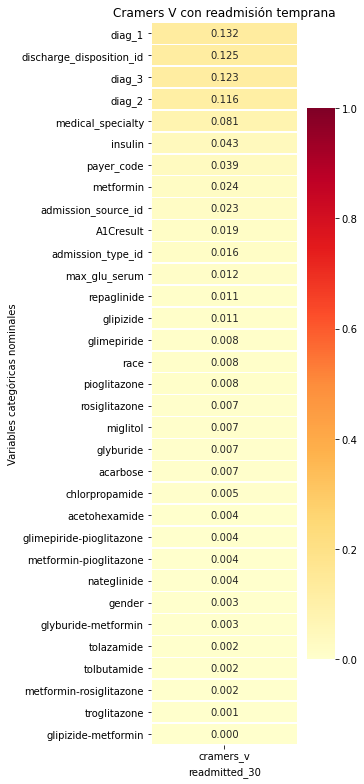

In [58]:
plt.figure(figsize=(5, 11))
sns.heatmap(df_cramer.set_index("variable")[["cramers_v"]], annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=0.5)
plt.title("Cramers V con readmisión temprana")
plt.xlabel("readmitted_30")
plt.ylabel("Variables categóricas nominales")
plt.tight_layout()
plt.show()

Interpretación: Las asociaciones entre las variables categóricas nominales y la readmisión temprana son débiles.

#### 4.5 Asociación entre variables ordinales y numéricas

Para analizar la relación entre las variables ordinales (`age` y `weight`) y las variables numéricas se utiliza **Kendall Tau**.

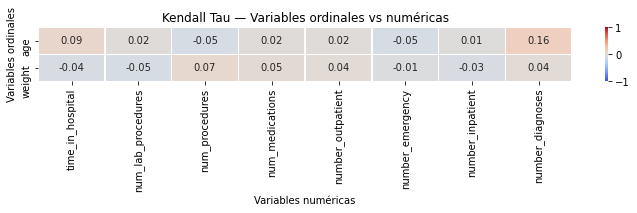

In [59]:
from scipy.stats import kendalltau

age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
weight_order = ["[0-25)", "[25-50)", "[50-75)", "[75-100)", "[100-125)", "[125-150)", "[150-175)", "[175-200)", ">200"]

ordinales = {"age": age_order, "weight": weight_order}
kendall_mat = pd.DataFrame(index=ordinales.keys(), columns=variables_numericas_raw, dtype=float)

for ord_col, orden in ordinales.items():
    ordinal = df_raw[ord_col].map({cat: i for i, cat in enumerate(orden)})
    for num_col in variables_numericas_raw:
        datos = pd.DataFrame({"ordinal": ordinal, "numerica": df_raw[num_col]}).dropna()
        tau, _ = kendalltau(datos["ordinal"], datos["numerica"])
        kendall_mat.loc[ord_col, num_col] = tau

plt.figure(figsize=(10, 3))
sns.heatmap(kendall_mat.astype(float), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Kendall Tau — Variables ordinales vs numéricas")
plt.xlabel("Variables numéricas")
plt.ylabel("Variables ordinales")
plt.tight_layout()
plt.show()

Interpretación: Las asociaciones entre las variables ordinales y numéricas son débiles. 

#### 4.6 Asociación entre variables categóricas nominales

Para explorar posibles relaciones o redundancias entre variables categóricas nominales se calcula **Cramer's V** para un conjunto de variables clínicas y administrativas seleccionadas.


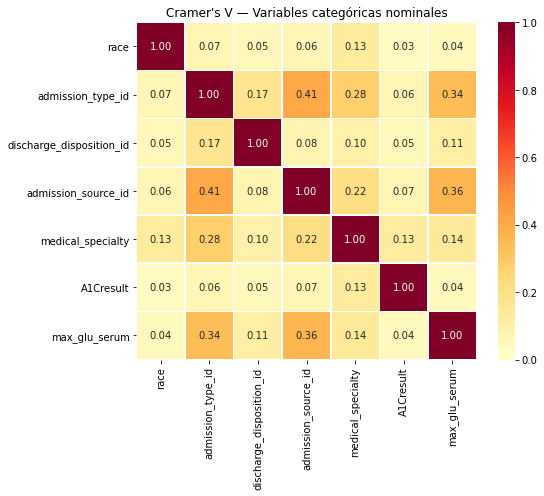

In [60]:
nominal_subset = ["race", "admission_type_id", "discharge_disposition_id", "admission_source_id", "medical_specialty", "A1Cresult", "max_glu_serum"]

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * min(tabla.shape[0] - 1, tabla.shape[1] - 1)))

cramer_mat = pd.DataFrame(index=nominal_subset, columns=nominal_subset, dtype=float)

for col1 in nominal_subset:
    for col2 in nominal_subset:
        if col1 == col2:
            cramer_mat.loc[col1, col2] = 1
        else:
            datos = df_raw[[col1, col2]].dropna()
            cramer_mat.loc[col1, col2] = cramers_v(datos[col1], datos[col2])

plt.figure(figsize=(8, 7))
sns.heatmap(cramer_mat, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=0.5)
plt.title("Cramer's V — Variables categóricas nominales")
plt.tight_layout()
plt.show()

Interpretación: La mayoría de las variables categóricas nominales presenta asociaciones débiles entre sí. La relación más destacada se observa entre `admission_type_id` y `admission_source_id` (V ≈ 0,41), seguida por `admission_source_id` con `max_glu_serum` (V ≈ 0,36) y `admission_type_id` con `max_glu_serum` (V ≈ 0,34).

### 5. Valores faltantes y outliers

#### 5.1 Errores e inconsistencias

In [61]:
print("Filas duplicadas:", df_raw.duplicated().sum())

Filas duplicadas: 0


In [62]:
print("encounter_id duplicados:", df_raw["encounter_id"].duplicated().sum())
print("encounter_id nulos:", df_raw["encounter_id"].isna().sum())
print("patient_nbr nulos:", df_raw["patient_nbr"].isna().sum())

encounter_id duplicados: 0
encounter_id nulos: 0
patient_nbr nulos: 0


In [63]:
print("gender:")
print(df_raw["gender"].value_counts(dropna=False))

print("\nrace:")
print(df_raw["race"].value_counts(dropna=False))

gender:
Female             54708
Male               47055
Unknown/Invalid        3
Name: gender, dtype: int64

race:
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: race, dtype: int64


In [64]:
validaciones = {
    "time_in_hospital fuera de 1-14": ~df_raw["time_in_hospital"].between(1, 14),
    "num_lab_procedures negativo": df_raw["num_lab_procedures"] < 0,
    "num_procedures negativo": df_raw["num_procedures"] < 0,
    "num_medications negativo": df_raw["num_medications"] < 0,
    "number_outpatient negativo": df_raw["number_outpatient"] < 0,
    "number_emergency negativo": df_raw["number_emergency"] < 0,
    "number_inpatient negativo": df_raw["number_inpatient"] < 0,
    "number_diagnoses negativo": df_raw["number_diagnoses"] < 0,
}

for descripcion, condicion in validaciones.items():
    print(f"{descripcion}: {condicion.sum()}")

time_in_hospital fuera de 1-14: 0
num_lab_procedures negativo: 0
num_procedures negativo: 0
num_medications negativo: 0
number_outpatient negativo: 0
number_emergency negativo: 0
number_inpatient negativo: 0
number_diagnoses negativo: 0


In [65]:
esperados = {
    "gender": {"Female", "Male", "Unknown/Invalid"},
    "readmitted": {"NO", ">30", "<30"},
    "change": {"No", "Ch"},
    "diabetesMed": {"No", "Yes"}
}

for col, valores in esperados.items():
    print(col, "valores inesperados:", set(df_raw[col].dropna().unique()) - valores)

gender valores inesperados: set()
readmitted valores inesperados: set()
change valores inesperados: set()
diabetesMed valores inesperados: set()


Interpretación: No se encontraron filas completamente duplicadas ni valores numéricos imposibles en las variables analizadas. Se detectaron únicamente 3 registros con `gender = "Unknown/Invalid"`, que deberán considerarse durante la limpieza. Los valores faltantes observados en otras variables, como `race`, serán analizados por separado en la sección correspondiente.

#### 5.2 Cuantificación de NaN

In [66]:
missing = pd.DataFrame({
    "cantidad": df_raw.isna().sum(),
    "porcentaje_%": df_raw.isna().mean() * 100
})

missing = (
    missing[missing["cantidad"] > 0]
    .sort_values("porcentaje_%", ascending=False)
)

missing.round(2)

,cantidad,porcentaje_%
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


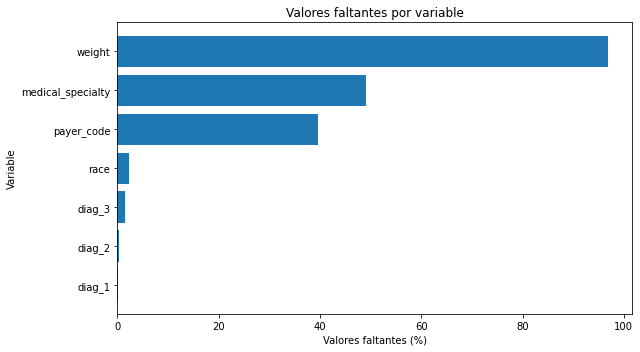

In [67]:
plt.figure(figsize=(9, 5))
plt.barh(
    missing.index[::-1],
    missing["porcentaje_%"][::-1]
)
plt.title("Valores faltantes por variable")
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

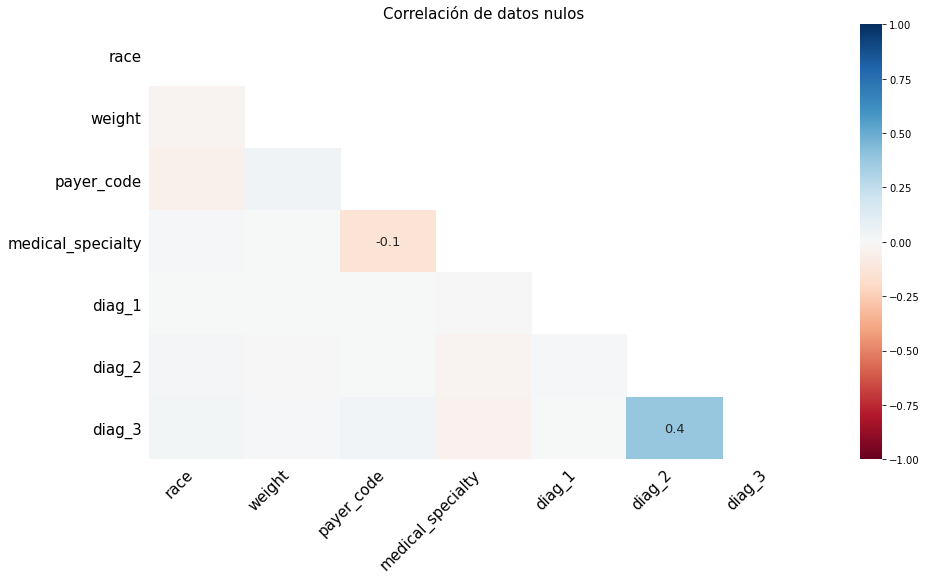

In [69]:
import missingno as msno

msno.heatmap(df_raw, fontsize=15, figsize=(15,8))
plt.title("Correlación de datos nulos", fontsize=15)
plt.show()

Interpretación: Se observa que hay una leve correlación entre los datos faltantes de `diag_2` y `diag_3`, lo que sugiere que la ausencia de información tiende a ocurrir de manera conjunta.

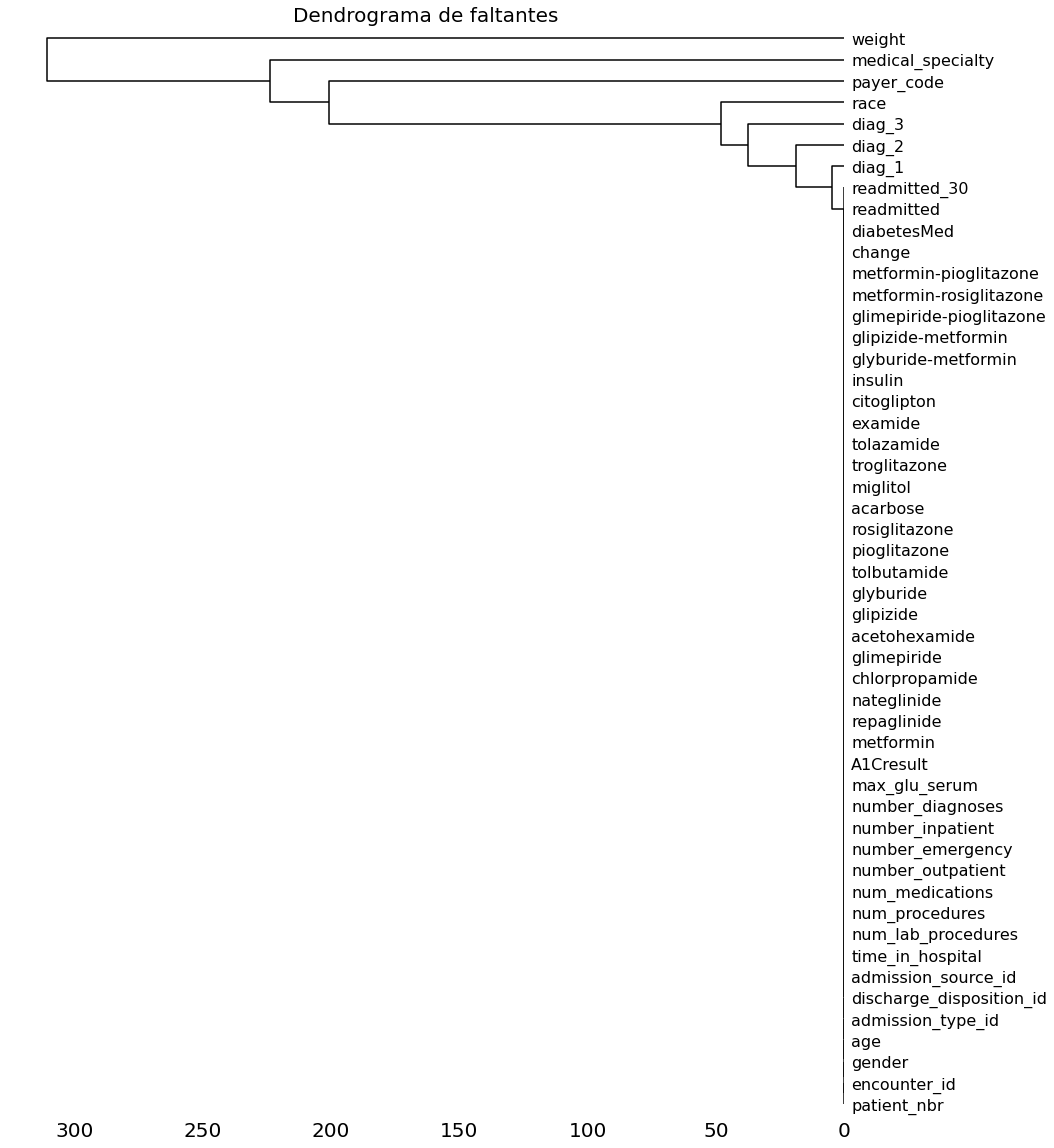

In [70]:
msno.dendrogram(df_raw, figsize=(15,20))
plt.title('Dendrograma de faltantes', fontsize=20)
plt.show()

Interpretación: El dendrograma sugiere que los faltantes no siguen un único patrón en todo el dataset.

`weight` presenta un patrón de ausencia muy diferente al resto. Por otro lado, `diag_2` y `diag_3` aparecen próximos entre sí, reforzando la idea de que sus valores faltantes pueden estar relacionados con un mismo proceso de registro de diagnósticos.

`payer_code` y `medical_specialty` también muestran cierta proximidad, posiblemente asociada a información administrativa que no siempre fue registrada.

La mayoría de las variables restantes se agrupan muy cerca de distancia cero principalmente porque prácticamente no presentan valores faltantes, por lo que ese agrupamiento aporta poca información adicional.

#### 5.3 Análisis del mecanismo de faltantes

Se corrobará el tipo de valores faltantes para las 6 variables con mayor % de datos faltantes según la clasificación:
- **MCAR:** la falta del dato es aleatoria y no depende de ninguna variable.
- **MAR:** la falta del dato depende de otras variables observadas.
- **MNAR:** la falta del dato depende del dato en sí mismo.
- **Estructural/por diseño:** la falta de valor se debe a que el dato no existe.

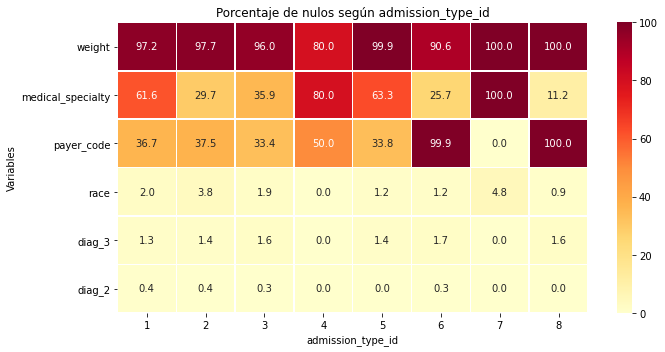

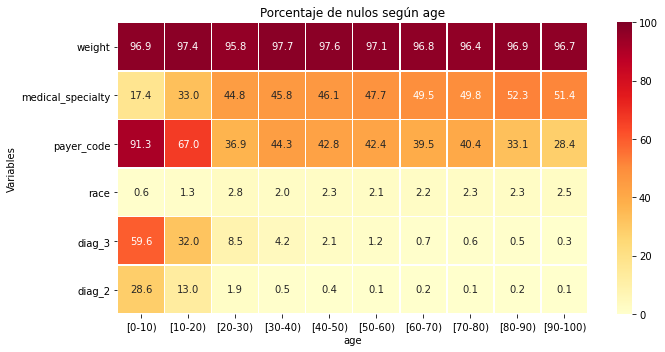

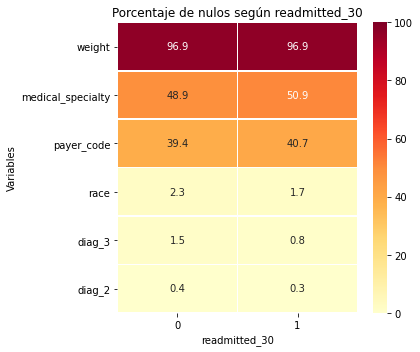

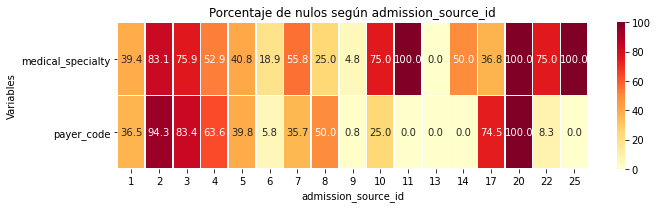

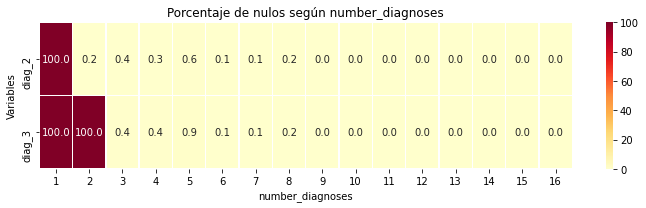

In [72]:
faltantes_top6 = ["weight", "medical_specialty", "payer_code", "race", "diag_3", "diag_2"]

def heatmap_nulos(df, group_col, target_cols, figsize=(10, 5), cmap="YlOrRd"):
    tabla = pd.DataFrame({
        col: df.groupby(group_col, observed=True)[col].apply(lambda x: x.isnull().mean() * 100)
        for col in target_cols
    }).T

    plt.figure(figsize=figsize)
    sns.heatmap(tabla, annot=True, fmt=".1f", cmap=cmap, vmin=0, vmax=100, linewidths=0.5)
    plt.title(f"Porcentaje de nulos según {group_col}")
    plt.xlabel(group_col)
    plt.ylabel("Variables")
    plt.tight_layout()
    plt.show()
    
heatmap_nulos(df_raw, "admission_type_id", faltantes_top6, figsize=(10, 5))
heatmap_nulos(df_raw, "age", faltantes_top6, figsize=(10, 5))
heatmap_nulos(df_raw, "readmitted_30", faltantes_top6, figsize=(6, 5))
heatmap_nulos(df_raw, "admission_source_id", ["medical_specialty", "payer_code"], figsize=(10, 3))
heatmap_nulos(df_raw, "number_diagnoses", ["diag_2", "diag_3"], figsize=(10, 3))

Interpretación:

El análisis por grupos muestra que los mecanismos de ausencia no son iguales para todas las variables.

- **`weight`**: el porcentaje de faltantes se mantiene prácticamente constante entre las variables. No se observa una dependencia clara con las variables analizadas, por lo que su comportamiento es compatible con **MCAR**. 

- **`medical_specialty`**: presenta variaciones importantes según el tipo y la fuente de admisión. Los faltantes son especialmente elevados en determinados circuitos de ingreso (`admission_type_id`), como emergencias (1), trauma (7), recién nacidos (4) y algunas derivaciones o transferencias (`admission_source_id`). Además, el porcentaje de ausencia aumenta con la edad. Esto sugiere que el registro de la especialidad médica está condicionado por características observables del encuentro y del circuito asistencial, por lo que su mecanismo de ausencia es compatible con **MAR**.

- **`payer_code`**: los faltantes no se distribuyen de manera aleatoria. Se ve una tendencia con respecto al rango etario, donde se ve un pocentaje de faltantes alto en los pacientes más jóvenes y disminuye progresivamente. Esto sugiere que el registor del pagador está relacionado con características demográficas y administrativas. Además, `payer_code` se encuentra prácticamente siempre ausente cuando `admission_type_id` corresponde a categorías administrativas sin información o no mapeadas (`NULL` y `Not Mapped`). Esto sugiere que ambas variables pueden formar parte de un mismo proceso de registro incompleto. Por lo tanto, el mecanismo de ausencia es compatible con **MAR**.

- **`diag_2` y `diag_3`**: el patrón sugiere principalmente un **faltante estructural**. `diag_2` falta siempre cuando existe un único diagnóstico, mientras que `diag_3` falta siempre cuando existen uno o dos diagnósticos. En esos casos el dato no está ausente por un problema de registro, sino porque simplemente no existe un segundo o tercer diagnóstico para informar.

- **`race`**: los porcentajes de faltantes son bajos y relativamente similares entre la mayoría de los grupos. No aparece un patrón fuerte de dependencia, por lo que puede considerarse compatible con **MCAR** para este análisis.

#### 5.4 Análisis de outliers

Detección mediante IQR

In [73]:
df_num = df_raw[variables_numericas_raw].copy()

Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1

lim_inf_iqr = Q1 - 1.5 * IQR
lim_sup_iqr = Q3 + 1.5 * IQR

outliers_iqr = (df_num < lim_inf_iqr) | (df_num > lim_sup_iqr)

resumen_iqr = pd.DataFrame({
    "limite_inferior": lim_inf_iqr,
    "limite_superior": lim_sup_iqr,
    "cantidad_outliers": outliers_iqr.sum(),
    "porcentaje_outliers": outliers_iqr.mean() * 100
}).round(2)

resumen_iqr

,limite_inferior,limite_superior,cantidad_outliers,porcentaje_outliers
time_in_hospital,-4.0,12.0,2252,2.21
num_lab_procedures,-8.0,96.0,143,0.14
num_procedures,-3.0,5.0,4954,4.87
num_medications,-5.0,35.0,2557,2.51
number_outpatient,0.0,0.0,16739,16.45
number_emergency,0.0,0.0,11383,11.19
number_inpatient,-1.5,2.5,7049,6.93
number_diagnoses,1.5,13.5,281,0.28


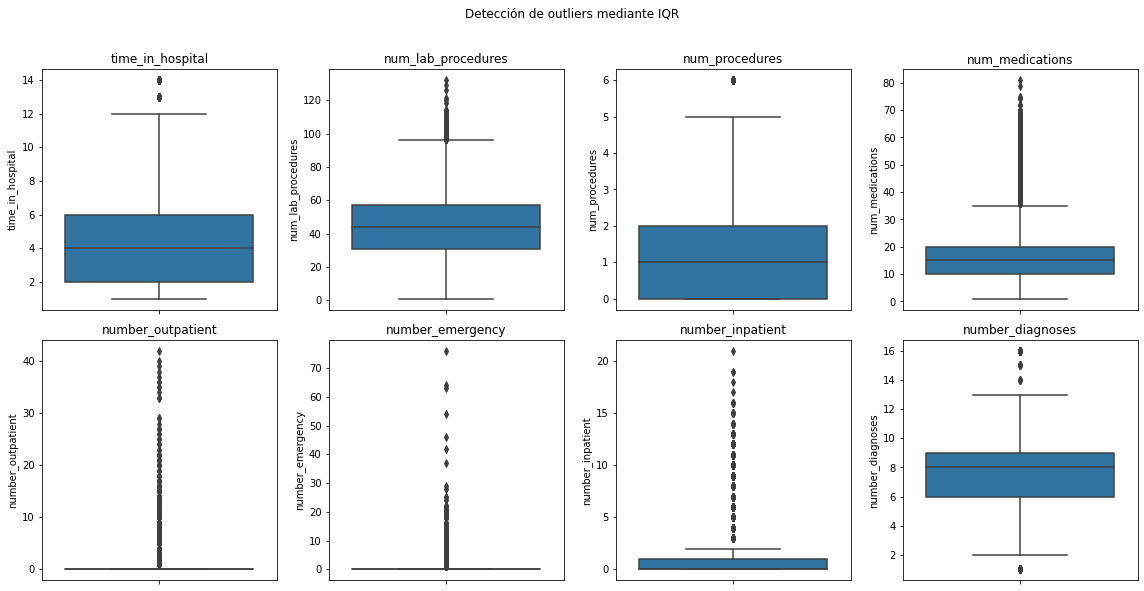

In [74]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, variables_numericas_raw):
    sns.boxplot(y=df_num[col], ax=ax)
    ax.set_title(col)

plt.suptitle("Detección de outliers mediante IQR", y=1.02)
plt.tight_layout()
plt.show()

Interpretación: Según el criterio IQR, varias variables presentan valores atípicos, especialmente `number_outpatient`, `number_emergency`, `number_inpatient` y `num_medications`. Estas variables se concentran principalmente en valores bajos, en muchos casos cercanos a 0, y presentan una cola hacia valores altos. Por eso, los valores extremos son identificados como outliers por el IQR, aunque no necesariamente representan errores, sino casos poco frecuentes con mayor utilización de recursos o mayor complejidad clínica.

Detección mediante desviación estándar

In [75]:
media = df_num.mean()
std = df_num.apply(lambda x: np.nanstd(x, ddof=1))

lim_inf_std = media - 3 * std
lim_sup_std = media + 3 * std

outliers_std = (df_num < lim_inf_std) | (df_num > lim_sup_std)

resumen_std = pd.DataFrame({
    "limite_inferior": lim_inf_std,
    "limite_superior": lim_sup_std,
    "cantidad_outliers": outliers_std.sum(),
    "porcentaje_outliers": outliers_std.mean() * 100
}).round(2)

resumen_std

,limite_inferior,limite_superior,cantidad_outliers,porcentaje_outliers
time_in_hospital,-4.56,13.35,1042,1.02
num_lab_procedures,-15.93,102.12,43,0.04
num_procedures,-3.78,6.46,0,0.00
num_medications,-8.36,40.40,1361,1.34
number_outpatient,-3.43,4.17,1457,1.43
number_emergency,-2.59,2.99,1664,1.64
number_inpatient,-3.15,4.42,2016,1.98
number_diagnoses,1.62,13.22,281,0.28


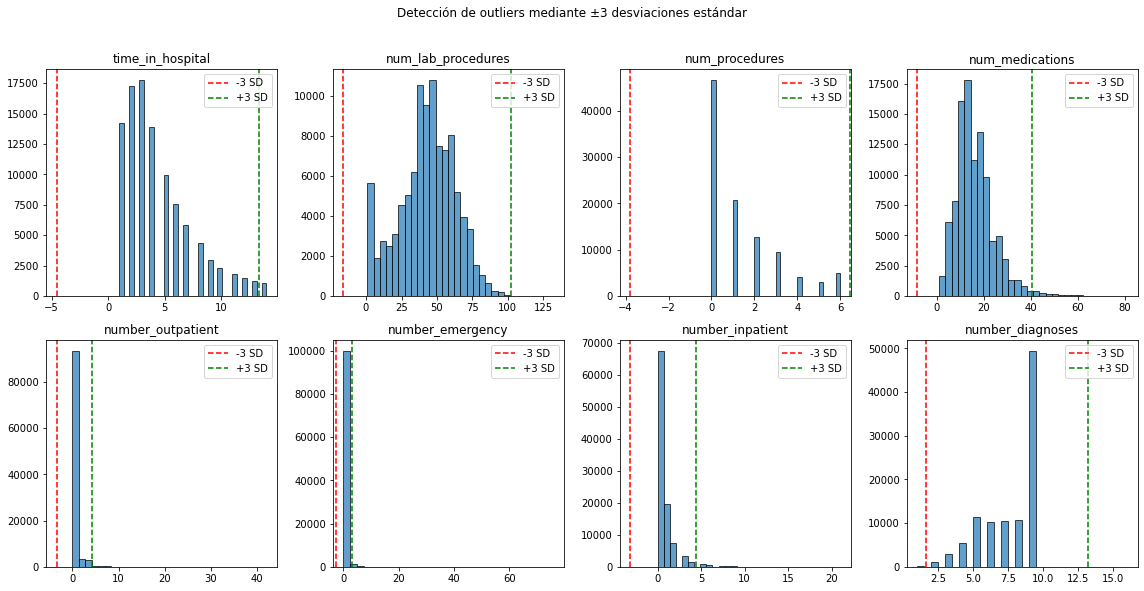

In [76]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, variables_numericas_raw):
    ax.hist(df_num[col].dropna(), bins=30, edgecolor="black", alpha=0.7)
    ax.axvline(lim_inf_std[col], color="red", linestyle="--", label="-3 SD")
    ax.axvline(lim_sup_std[col], color="green", linestyle="--", label="+3 SD")
    ax.set_title(col)
    ax.legend()

plt.suptitle("Detección de outliers mediante ±3 desviaciones estándar", y=1.02)
plt.tight_layout()
plt.show()

Interpretación: E algunos casos, el criterio basado en ±3 STD genera límites inferiores negativos que no tienen sentido dentro del dominio de los datos, ya que se trata de variables de conteo que no pueden tomar valores negativos. 
Por este motivo, este método se considera únicamente como referencia comparativa. Para la identificación de posibles outliers se priorizará el criterio basado en IQR.

### 6. Planteo del problema de ML supervisado

Como se exploró hasta ahora en el trabajo, se plantea un problema de clasificación binaria cuyo objetivo es predecir si un encuentro hospitalario terminará en una readmisión temprana, definida como una nueva internación dentro de los 30 días posteriores al alta.

A partir de la variable original `readmitted`, que posee las categorías `<30`, `>30` y `NO`, se construyó la variable objetivo `readmitted_30`:

- `1`: el paciente fue readmitido dentro de los 30 días.
- `0`: el paciente no fue readmitido dentro de los 30 días (`NO` o `>30`).

Por lo tanto, el objetivo del modelo será identificar qué características clínicas, demográficas y del encuentro hospitalario se asocian con un mayor riesgo de readmisión temprana.

### 7. Preprocesamiento

In [77]:
df_modelo = df_raw.copy()

# La variable original contiene la información usada para construir el target
df_modelo = df_modelo.drop(columns=["readmitted"])

# Identificadores: no aportan información clínica predictiva
# patient_nbr se conserva temporalmente para realizar correctamente el split
df_modelo = df_modelo.drop(columns=["encounter_id"])

# Variable con 97% de faltantes
df_modelo = df_modelo.drop(columns=["weight"])

# Variable con 40% de faltantes y sin relevancia para el outcome
df_modelo = df_modelo.drop(columns=["payer_code"])

# Tratar la categoría Unknown como NaN
df_modelo["gender"] = df_modelo["gender"].replace("Unknown/Invalid", np.nan)

In [78]:
df_raw[["examide", "citoglipton"]].nunique()


examide        1
citoglipton    1
dtype: int64

In [79]:
# Variables sin variabilidad
df_modelo = df_modelo.drop(columns=["examide", "citoglipton"])

In [80]:
# Exclusión de encuentros sin oportunidad comparable de readmisión (fallecimiento u hospice)
discharge_excluir = [11, 13, 14, 19, 20, 21]

print("Encuentros a excluir:", df_modelo["discharge_disposition_id"].isin(discharge_excluir).sum())

df_modelo = df_modelo[~df_modelo["discharge_disposition_id"].isin(discharge_excluir)].copy()

print("Shape luego de la exclusión:", df_modelo.shape)

Encuentros a excluir: 2423
Shape luego de la exclusión: (99343, 45)


#### 7.1 Split train test

El dataset contiene múltiples encuentros correspondientes a un mismo paciente. Por este motivo, la separación entre train y test se realiza agrupando por `patient_nbr`, evitando que encuentros del mismo paciente aparezcan en ambos conjuntos y produzcan fuga de información.

Además, debido al desbalance de la variable objetivo, se utiliza una separación estratificada para conservar aproximadamente la proporción de readmisiones tempranas en ambos conjuntos.

In [81]:
from sklearn.model_selection import StratifiedGroupKFold

X = df_modelo.drop(columns=["readmitted_30"])
y = df_modelo["readmitted_30"]
grupos = df_modelo["patient_nbr"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups=grupos))

train = df_modelo.iloc[train_idx].copy()
test = df_modelo.iloc[test_idx].copy()

print("Train:", train.shape)
print("Test:", test.shape)
print("\nTarget train:")
print(train["readmitted_30"].value_counts(normalize=True).round(4))
print("\nTarget test:")
print(test["readmitted_30"].value_counts(normalize=True).round(4))
print("\nPacientes compartidos:", len(set(train["patient_nbr"]) & set(test["patient_nbr"])))

Train: (79625, 45)
Test: (19718, 45)

Target train:
0    0.8854
1    0.1146
Name: readmitted_30, dtype: float64

Target test:
0    0.889
1    0.111
Name: readmitted_30, dtype: float64

Pacientes compartidos: 0


In [82]:
train = train.drop(columns=["patient_nbr"])
test = test.drop(columns=["patient_nbr"])

X_train = train.drop(columns=["readmitted_30"])
y_train = train["readmitted_30"]

X_test = test.drop(columns=["readmitted_30"])
y_test = test["readmitted_30"]

`patient_nbr` identifica de forma única a cada paciente. Como un mismo paciente puede presentar múltiples encuentros hospitalarios, se conserva temporalmente para realizar el split por paciente, evitando que registros del mismo individuo aparezcan en ambos conjuntos y generen fuga de información. Una vez realizado el split, esta variable se elimina del conjunto de predictores.

#### 7.2 Tratamiento de datos faltantes

- `weight` fue eliminada debido a que presenta aproximadamente un 97% de valores faltantes.
- `payer_code` fue eliminada por presentar alrededor de un 40% de faltantes y baja relevancia para el problema planteado.
- En `medical_specialty` se conserva la ausencia como una categoría `"Missing"`, ya que el faltante presenta un patrón MAR y puede contener información relacionada con el circuito asistencial.
- Para `race`, `gender` y `diag_1`, debido a la muy baja cantidad de registros afectados, se eliminan las observaciones con valores faltantes.
- Los faltantes de `diag_2` y `diag_3` son principalmente estructurales. Se utiliza `"No_aplica"` cuando el segundo o tercer diagnóstico no existe y se eliminarán las filas cuyas ausencias que no pueden explicarse por la cantidad de diagnósticos registrados.

In [83]:
# Eliminación de filas con NaN en race, gender y diag_1
cols_eliminar_filas = ["race", "gender", "diag_1"]

mask_train = X_train[cols_eliminar_filas].notna().all(axis=1)
X_train, y_train = X_train.loc[mask_train].copy(), y_train.loc[mask_train].copy()

mask_test = X_test[cols_eliminar_filas].notna().all(axis=1)
X_test, y_test = X_test.loc[mask_test].copy(), y_test.loc[mask_test].copy()

In [84]:
# Generación de clase Missing en Medical_Specialty
X_train["medical_specialty"] = X_train["medical_specialty"].fillna("Missing")
X_test["medical_specialty"] = X_test["medical_specialty"].fillna("Missing")

In [85]:
# Creación de No_aplica para NaN de naturaleza estructural
for df in [X_train, X_test]:
    df.loc[df["diag_2"].isna() & (df["number_diagnoses"] == 1), "diag_2"] = "No_aplica"
    df.loc[df["diag_3"].isna() & (df["number_diagnoses"] <= 2), "diag_3"] = "No_aplica"

In [86]:
print(X_train[["diag_2", "diag_3"]].isna().sum())

diag_2    102
diag_3    122
dtype: int64


In [87]:
# Eliminación de NaN remanentes de diag_2 y diag_3

mask_train = X_train[["diag_2", "diag_3"]].notna().all(axis=1)
X_train, y_train = X_train.loc[mask_train].copy(), y_train.loc[mask_train].copy()

mask_test = X_test[["diag_2", "diag_3"]].notna().all(axis=1)
X_test, y_test = X_test.loc[mask_test].copy(), y_test.loc[mask_test].copy()

In [88]:
#Corroboración de que no hay más NaN 
pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()}).query("train > 0 or test > 0")

,train,test


#### 7.3 Tratamiento de outliers

El análisis mediante IQR identificó numerosos valores atípicos, principalmente en variables de conteo como `number_outpatient`, `number_emergency`, `number_inpatient` y `num_medications`.

Sin embargo, estas variables presentan distribuciones asimétricas y una gran concentración en 0 en algunos casos. Por este motivo, el criterio IQR clasifica como atípicos valores que pueden representar situaciones clínicas reales, como pacientes con múltiples consultas, internaciones o mayor cantidad de medicación.

Además, durante el análisis de inconsistencias no se detectaron valores imposibles en estas variables (por ejemplo cantidad de días de internación negativos o mayores a 14). Por lo tanto, se decide **no eliminar ni reemplazar los outliers**, ya que podrían contener información relevante para predecir la readmisión temprana.

#### 7.4 Agrupación de diagnósticos

Las variables `diag_1`, `diag_2` y `diag_3` contienen códigos ICD-9 y presentan una alta cardinalidad. Para reducir la dimensionalidad y conservar una interpretación clínica, los códigos se agrupan en categorías diagnósticas generales siguiendo la clasificación utilizada por Strack et al. (2014): circulatorias, respiratorias, digestivas, diabetes, lesiones, musculoesqueléticas, genitourinarias, neoplasias y otros diagnósticos.

In [89]:
def agrupar_diagnostico(x):
    if x == "No_aplica":
        return "No_aplica"
    try:
        codigo = float(x)
    except:
        return "Other"

    if 390 <= codigo <= 459 or codigo == 785:
        return "Circulatory"
    elif 460 <= codigo <= 519 or codigo == 786:
        return "Respiratory"
    elif 520 <= codigo <= 579 or codigo == 787:
        return "Digestive"
    elif 250 <= codigo < 251:
        return "Diabetes"
    elif 800 <= codigo <= 999:
        return "Injury"
    elif 710 <= codigo <= 739:
        return "Musculoskeletal"
    elif 580 <= codigo <= 629 or codigo == 788:
        return "Genitourinary"
    elif 140 <= codigo <= 239:
        return "Neoplasms"
    else:
        return "Other"

In [90]:
for df in [X_train, X_test]:
    for col in ["diag_1", "diag_2", "diag_3"]:
        df[col] = df[col].apply(agrupar_diagnostico)

In [91]:
for col in ["diag_1", "diag_2", "diag_3"]:
    print(f"\n{col}")
    print(X_train[col].value_counts())


diag_1
Circulatory        23213
Other              13876
Respiratory        10917
Digestive           7377
Diabetes            6758
Injury              5314
Genitourinary       3973
Musculoskeletal     3826
Neoplasms           2428
Name: diag_1, dtype: int64

diag_2
Circulatory        24485
Other              20316
Diabetes           10011
Respiratory         8117
Genitourinary       6367
Digestive           3194
Injury              1849
Neoplasms           1805
Musculoskeletal     1367
No_aplica            171
Name: diag_2, dtype: int64

diag_3
Circulatory        23253
Other              22324
Diabetes           13294
Respiratory         5462
Genitourinary       5109
Digestive           3006
Musculoskeletal     1489
Injury              1477
Neoplasms           1308
No_aplica            960
Name: diag_3, dtype: int64


#### 7.5 Reducción de cardinalidad de medical_specialty

`medical_specialty` presenta una elevada cantidad de categorías, muchas de ellas con muy pocas observaciones. Para evitar generar un número excesivo de variables durante el One-Hot Encoding, se agrupan como `Other` aquellas especialidades que representan menos del 1% de las observaciones del conjunto de entrenamiento.

In [92]:
print(X_train["medical_specialty"].nunique())
print(X_train["medical_specialty"].value_counts(normalize=True).head(20))

71
Missing                              0.490191
InternalMedicine                     0.141178
Emergency/Trauma                     0.076247
Family/GeneralPractice               0.072938
Cardiology                           0.053449
Surgery-General                      0.031037
Nephrology                           0.015885
Orthopedics                          0.014083
Orthopedics-Reconstructive           0.012165
Radiologist                          0.011393
Psychiatry                           0.008303
Pulmonology                          0.008084
Urology                              0.006848
ObstetricsandGynecology              0.006694
Surgery-Cardiovascular/Thoracic      0.006385
Surgery-Vascular                     0.005523
Gastroenterology                     0.005445
Surgery-Neuro                        0.004506
PhysicalMedicineandRehabilitation    0.003810
Oncology                             0.003257
Name: medical_specialty, dtype: float64


In [93]:
freq = X_train["medical_specialty"].value_counts(normalize=True)
especialidades_frecuentes = freq[freq >= 0.01].index

X_train["medical_specialty"] = X_train["medical_specialty"].where(X_train["medical_specialty"].isin(especialidades_frecuentes), "Other")
X_test["medical_specialty"] = X_test["medical_specialty"].where(X_test["medical_specialty"].isin(especialidades_frecuentes), "Other")

In [94]:
X_train["medical_specialty"].value_counts()

Missing                       38079
InternalMedicine              10967
Other                          6326
Emergency/Trauma               5923
Family/GeneralPractice         5666
Cardiology                     4152
Surgery-General                2411
Nephrology                     1234
Orthopedics                    1094
Orthopedics-Reconstructive      945
Radiologist                     885
Name: medical_specialty, dtype: int64

In [95]:
# para probar SMOTENC
X_train_smotenc = X_train.copy()
y_train_smotenc = y_train.copy()

#### 7.6 Codificación de variables categóricas. One Hot Encoding

- `age` se codifica de forma ordinal, respetando el orden de los rangos etarios.
- `change` y `diabetesMed` se transforman a variables binarias.
- Las variables categóricas nominales se codifican mediante One-Hot Encoding, evitando asignar un orden artificial entre sus categorías.

In [96]:
age_order = ["[0-10)","[10-20)","[20-30)","[30-40)","[40-50)","[50-60)","[60-70)","[70-80)","[80-90)","[90-100)"]
age_map = {edad:i for i, edad in enumerate(age_order)}

for df in [X_train, X_test]:
    df["age"] = df["age"].map(age_map)
    df["gender"] = df["gender"].map({"Female":0, "Male":1})
    df["change"] = df["change"].map({"No":0, "Ch":1})
    df["diabetesMed"] = df["diabetesMed"].map({"No":0, "Yes":1})

In [97]:
nominales_id = ["admission_type_id","discharge_disposition_id","admission_source_id"]
variables_nominales = X_train.select_dtypes(include=["object"]).columns.tolist() + nominales_id

In [98]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_encoded = encoder.fit_transform(X_train[variables_nominales])
test_encoded = encoder.transform(X_test[variables_nominales])

cols_encoded = encoder.get_feature_names_out(variables_nominales)

train_encoded = pd.DataFrame(train_encoded, columns=cols_encoded, index=X_train.index)
test_encoded = pd.DataFrame(test_encoded, columns=cols_encoded, index=X_test.index)

In [99]:
X_train = pd.concat([X_train.drop(columns=variables_nominales), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=variables_nominales), test_encoded], axis=1)

print(X_train.shape)
print(X_test.shape)

(77682, 178)
(19184, 178)


In [100]:
print("NaN train:", X_train.isna().sum().sum())
print("NaN test:", X_test.isna().sum().sum())
print("Columnas iguales:", list(X_train.columns) == list(X_test.columns))

NaN train: 0
NaN test: 0
Columnas iguales: True


#### 7.7 Escalado de variables numéricas + age

Las variables numéricas presentan escalas diferentes y varias de ellas muestran distribuciones asimétricas con presencia de valores extremos. Como estos valores fueron considerados clínicamente plausibles y se decidió conservarlos, se utiliza RobustScaler.

Este método centra las variables utilizando la mediana y las escala según el rango intercuartílico (IQR), por lo que resulta menos sensible a valores extremos que una estandarización basada en media y desvío estándar.

Se escalan las variables numéricas originales y `age`, previamente codificada de forma ordinal. Las variables binarias y las generadas mediante One-Hot Encoding no se escalan, ya que ya se encuentran representadas mediante valores 0/1.

In [101]:
from sklearn.preprocessing import RobustScaler

cols_escalar = variables_numericas_raw + ["age"]

scaler = RobustScaler()
X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test[cols_escalar] = scaler.transform(X_test[cols_escalar])

In [102]:
X_train[cols_escalar].describe().round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age
count,77682.00,77682.00,77682.00,77682.00,77682.00,77682.00,77682.00,77682.00,77682.00
mean,0.10,-0.04,0.17,0.10,0.37,0.20,0.64,-0.19,0.04
std,0.74,0.76,0.85,0.81,1.28,0.95,1.26,0.64,0.80
min,-0.75,-1.65,-0.50,-1.40,0.00,0.00,0.00,-2.33,-3.00
25%,-0.50,-0.50,-0.50,-0.50,0.00,0.00,0.00,-0.67,-0.50
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.50,0.50,0.50,0.50,0.00,0.00,1.00,0.33,0.50
max,2.50,3.38,2.50,6.60,42.00,76.00,19.00,2.67,1.50


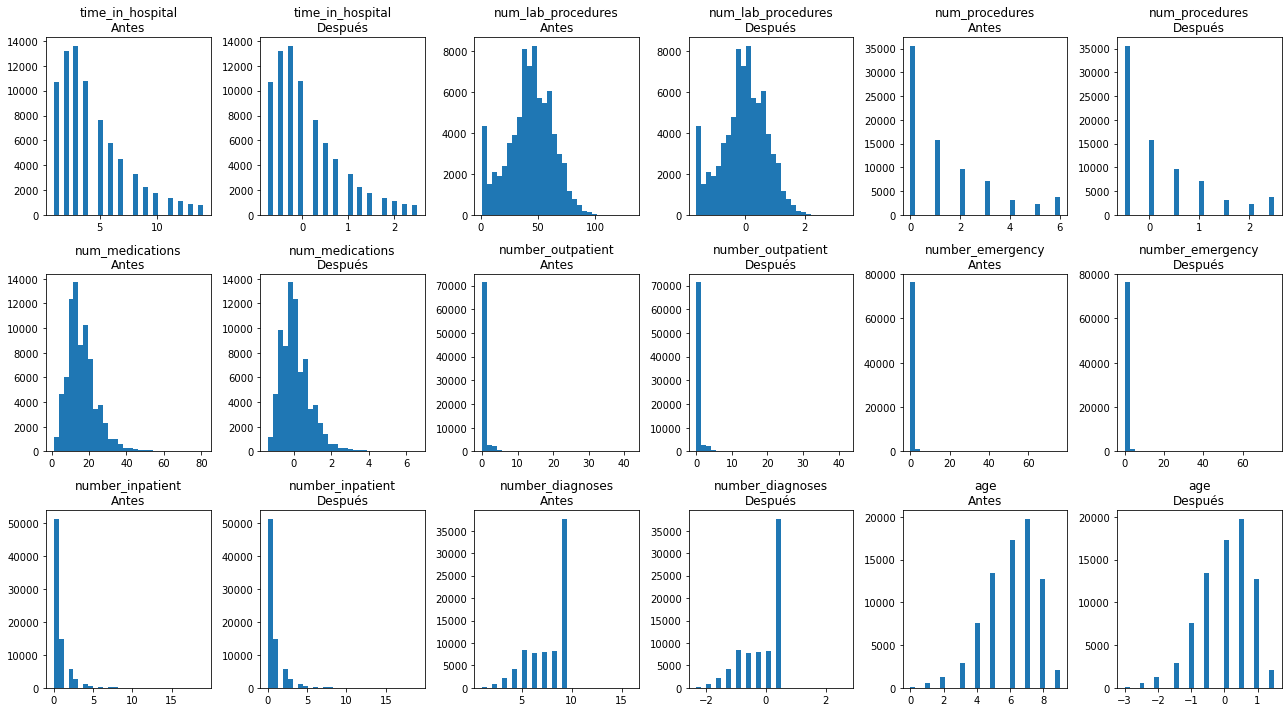

In [103]:
X_train_antes = X_train.copy()
X_train_antes[cols_escalar] = scaler.inverse_transform(X_train[cols_escalar])

# Histogramas antes vs después
fig, axes = plt.subplots(3, 6, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cols_escalar):
    axes[2*i].hist(X_train_antes[col], bins=30)
    axes[2*i].set_title(f"{col}\nAntes")
    
    axes[2*i+1].hist(X_train[col], bins=30)
    axes[2*i+1].set_title(f"{col}\nDespués")

plt.tight_layout()
plt.show()

### 8. Feature engineering

#### 8.1 Desbalance de clases

La variable objetivo presenta un desbalance entre las clases de readmisión temprana y no readmisión temprana. Se analiza la proporción de las clases y la entropía de Shannon para cuantificar el grado de desbalance.

In [104]:
def shannon_entropy(y):
    probs = y.value_counts(normalize=True)
    return -np.sum(probs*np.log2(probs))

print("Proporción de clases:")
print(y_train.value_counts(normalize=True).round(4))
print("\nCantidad:")
print(y_train.value_counts())
print("\nEntropía de Shannon:", round(shannon_entropy(y_train), 4))
print("Ratio mayoritaria/minoritaria:", round(y_train.value_counts().max()/y_train.value_counts().min(), 2))

Proporción de clases:
0    0.8848
1    0.1152
Name: readmitted_30, dtype: float64

Cantidad:
0    68734
1     8948
Name: readmitted_30, dtype: int64

Entropía de Shannon: 0.5154
Ratio mayoritaria/minoritaria: 7.68


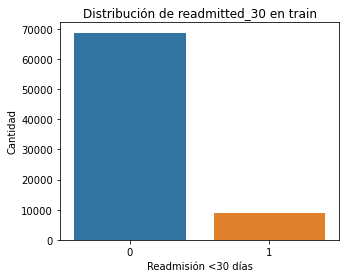

In [105]:
import seaborn as sns

plt.figure(figsize=(5,4))
sns.countplot(x=y_train)
plt.title("Distribución de readmitted_30 en train")
plt.xlabel("Readmisión <30 días")
plt.ylabel("Cantidad")
plt.show()

Interpretación: La clase positiva representa únicamente el 11,5% de las observaciones de entrenamiento, con aproximadamente 8 registros de la clase mayoritaria por cada registro de readmisión temprana. La entropía de Shannon de 0,5 confirma un desbalance considerable.

Dado que las distintas técnicas de balanceo pueden modificar de manera importante el conjunto de entrenamiento, se comparan experimentalmente oversampling, undersampling y SMOTE antes de seleccionar una estrategia definitiva.

##### 8.1.1 Comparación inicial de técnicas de balanceo


Se comparan tres estrategias básicas:

- **Random Oversampling:** aumenta la clase minoritaria mediante repetición aleatoria de observaciones existentes.
- **Random Undersampling:** reduce la clase mayoritaria eliminando observaciones de forma aleatoria.
- **SMOTE:** genera nuevas observaciones sintéticas de la clase minoritaria mediante interpolación entre observaciones cercanas.

Se conserva una copia del conjunto de entrenamiento original para poder comparar los resultados sin modificar los datos de partida.

In [106]:
X_train_original = X_train.copy()
y_train_original = y_train.copy()

In [107]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_train_original, y_train_original)

rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train_original, y_train_original)

smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train_original, y_train_original)

In [108]:
comparacion = pd.DataFrame({
    "Original": y_train_original.value_counts().sort_index(),
    "Oversampling": y_over.value_counts().sort_index(),
    "Undersampling": y_under.value_counts().sort_index(),
    "SMOTE": y_smote.value_counts().sort_index()
})

comparacion

,Original,Oversampling,Undersampling,SMOTE
0,68734,68734,8948,68734
1,8948,68734,8948,68734


El oversampling y SMOTE generan conjuntos balanceados con 68.734 observaciones en cada clase. Sin embargo, el oversampling alcanza este resultado mediante la repetición de ejemplos de la clase minoritaria, mientras que SMOTE genera nuevas observaciones sintéticas. Cabe aclarar que en ambas técnicas estamos generando aproximadamente 60 mil datos sintéticos de la clase 1.

El undersampling también obtiene un equilibrio perfecto, pero reduce la clase mayoritaria de 68.734 a 8.948 observaciones. Esto implica descartar una proporción muy importante de la información disponible, por lo que resulta menos conveniente.

Una limitación de aplicar SMOTE después del One-Hot Encoding es que el algoritmo interpola numéricamente entre observaciones sin considerar el significado original de las variables categóricas. Se verificará si las observaciones sintéticas contienen valores intermedios entre 0 y 1 en columnas que originalmente eran indicadores binarios One-Hot.

In [109]:
X_sinteticos = X_smote.iloc[len(X_train_original):]

valores_intermedios = ((X_sinteticos[cols_encoded] > 0) & (X_sinteticos[cols_encoded] < 1)).sum().sum()
print("Valores intermedios generados en columnas One-Hot:", valores_intermedios)

Valores intermedios generados en columnas One-Hot: 369280


In [110]:
X_sinteticos[cols_encoded]

,race_AfricanAmerican,race_Asian,race_Caucasian,race_Hispanic,race_Other,medical_specialty_Cardiology,medical_specialty_Emergency/Trauma,medical_specialty_Family/GeneralPractice,medical_specialty_InternalMedicine,medical_specialty_Missing,...,admission_source_id_7,admission_source_id_8,admission_source_id_9,admission_source_id_10,admission_source_id_13,admission_source_id_14,admission_source_id_17,admission_source_id_20,admission_source_id_22,admission_source_id_25
77682,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,0.089561,0.910439,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
77683,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,1.000000,0.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
77684,0.00000,0.0,1.00000,0.0,0.0,0.0,0.498181,0.000000,0.501819,0.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
77685,0.60703,0.0,0.39297,0.0,0.0,0.0,0.000000,0.000000,0.607030,0.392970,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
77686,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,0.000000,1.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137463,1.00000,0.0,0.00000,0.0,0.0,0.0,0.000000,0.885148,0.114852,0.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
137464,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,0.000000,1.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
137465,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
137466,0.00000,0.0,1.00000,0.0,0.0,0.0,0.000000,0.000000,1.000000,0.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


La aplicación de SMOTE generó 384.142 valores intermedios en las columnas provenientes del One-Hot Encoding. 
La variable `diag_3_Circulatory` fue utilizada como ejemplo para visualizar este efecto, presentando 12.803 valores intermedios luego de aplicar SMOTE.

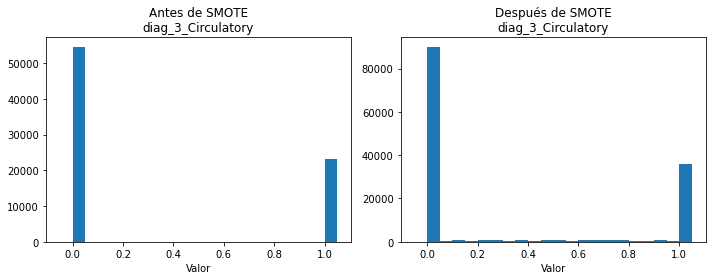

Variable: diag_3_Circulatory
Valores intermedios: 12081


In [111]:
intermedios = ((X_smote[cols_encoded] > 0) & (X_smote[cols_encoded] < 1)).sum()
col_ejemplo = intermedios.idxmax()

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].hist(X_train_original[col_ejemplo], bins=np.linspace(-0.05,1.05,23)); ax[0].set_title(f"Antes de SMOTE\n{col_ejemplo}"); ax[0].set_xlabel("Valor")
ax[1].hist(X_smote[col_ejemplo], bins=np.linspace(-0.05,1.05,23)); ax[1].set_title(f"Después de SMOTE\n{col_ejemplo}"); ax[1].set_xlabel("Valor")
plt.tight_layout(); plt.show()

print("Variable:", col_ejemplo)
print("Valores intermedios:", intermedios[col_ejemplo])

Como alternativa, se evalúa corregir las columnas One-Hot generadas por SMOTE mediante un umbral de 0,5: los valores menores a 0,5 se transforman en 0 y los mayores o iguales a 0,5 en 1.

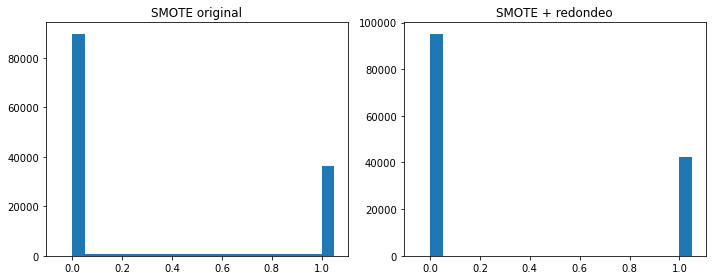

In [112]:
X_smote_round = X_smote.copy()
X_smote_round[cols_encoded] = (X_smote_round[cols_encoded] >= 0.5).astype(int)

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].hist(X_smote[col_ejemplo], bins=np.linspace(-0.05,1.05,23)); ax[0].set_title("SMOTE original")
ax[1].hist(X_smote_round[col_ejemplo], bins=np.linspace(-0.05,1.05,23)); ax[1].set_title("SMOTE + redondeo")
plt.tight_layout(); plt.show()

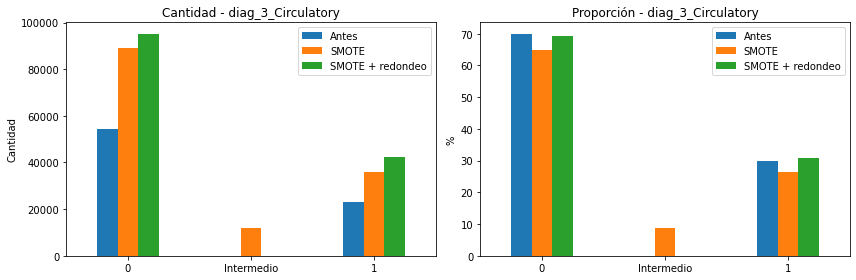

Variable: diag_3_Circulatory
            Antes  SMOTE  SMOTE + redondeo
0           54429  89265             95289
Intermedio      0  12081                 0
1           23253  36122             42179


In [113]:
intermedios = ((X_smote[cols_encoded] > 0) & (X_smote[cols_encoded] < 1)).sum()
col_ejemplo = intermedios.idxmax()

def clasificar_valor(x):
    if np.isclose(x, 0): return "0"
    if np.isclose(x, 1): return "1"
    return "Intermedio"

X_smote_round = X_smote.copy()
X_smote_round[cols_encoded] = (X_smote_round[cols_encoded] >= 0.5).astype(int)

antes = X_train_original[col_ejemplo].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)
smote = X_smote[col_ejemplo].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)
smote_round = X_smote_round[col_ejemplo].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)

comparacion = pd.DataFrame({
    "Antes": antes,
    "SMOTE": smote,
    "SMOTE + redondeo": smote_round
})

fig, ax = plt.subplots(1,2,figsize=(12,4))

comparacion.plot(kind="bar", ax=ax[0])
ax[0].set_title(f"Cantidad - {col_ejemplo}")
ax[0].set_ylabel("Cantidad")
ax[0].tick_params(axis="x", rotation=0)

(comparacion/comparacion.sum()*100).plot(kind="bar", ax=ax[1])
ax[1].set_title(f"Proporción - {col_ejemplo}")
ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Variable:", col_ejemplo)
print(comparacion)

Luego del redondeo no permanecen valores intermedios en las variables One-Hot. Sin embargo, el redondeo constituye una corrección posterior a la generación de las observaciones sintéticas y depende de un umbral arbitrario de 0,5.

Debido a que el dataset combina variables numéricas y categóricas, se evalúa también **SMOTENC**, una variante de SMOTE diseñada específicamente para datos mixtos.

A diferencia de SMOTE convencional, SMOTENC identifica explícitamente las variables categóricas y evita interpolarlas como si fueran variables continuas. Por esta razón, se aplica antes del One-Hot Encoding, conservando las categorías originales durante la generación de observaciones sintéticas.

In [114]:
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import RobustScaler

# Variables categóricas para SMOTENC
nominales_id = ["admission_type_id","discharge_disposition_id","admission_source_id"]
categoricas_smotenc = X_train_smotenc.select_dtypes(include="object").columns.tolist() + nominales_id

# Las paso a dtype category para que SMOTENC las reconozca
for col in categoricas_smotenc:
    X_train_smotenc[col] = X_train_smotenc[col].astype("category")

# Escalo solo las numéricas antes de calcular vecinos
scaler_smotenc = RobustScaler()
X_train_smotenc[variables_numericas_raw] = scaler_smotenc.fit_transform(X_train_smotenc[variables_numericas_raw])

# SMOTENC
smotenc = SMOTENC(categorical_features="auto", random_state=42)
X_smotenc, y_smotenc = smotenc.fit_resample(X_train_smotenc, y_train_smotenc)

print("Antes:")
print(y_train_smotenc.value_counts())

print("\nDespués de SMOTENC:")
print(y_smotenc.value_counts())

print("\nShape:", X_smotenc.shape)

Antes:
0    68734
1     8948
Name: readmitted_30, dtype: int64

Después de SMOTENC:
0    68734
1    68734
Name: readmitted_30, dtype: int64

Shape: (137468, 43)


In [115]:
metodos = {
    "Antes": y_train_original,
    "SMOTE": y_smote,
    "SMOTE + redondeo": y_smote,
    "SMOTENC": y_smotenc
}

comparacion_balance = pd.DataFrame({
    nombre: {
        "Clase 0": y.value_counts().get(0,0),
        "Clase 1": y.value_counts().get(1,0),
        "Total": len(y),
        "% clase 0": y.value_counts(normalize=True).get(0,0)*100,
        "% clase 1": y.value_counts(normalize=True).get(1,0)*100
    }
    for nombre, y in metodos.items()
}).T.round(2)

comparacion_balance

,Clase 0,Clase 1,Total,% clase 0,% clase 1
Antes,68734.0,8948.0,77682.0,88.48,11.52
SMOTE,68734.0,68734.0,137468.0,50.00,50.00
SMOTE + redondeo,68734.0,68734.0,137468.0,50.00,50.00
SMOTENC,68734.0,68734.0,137468.0,50.00,50.00


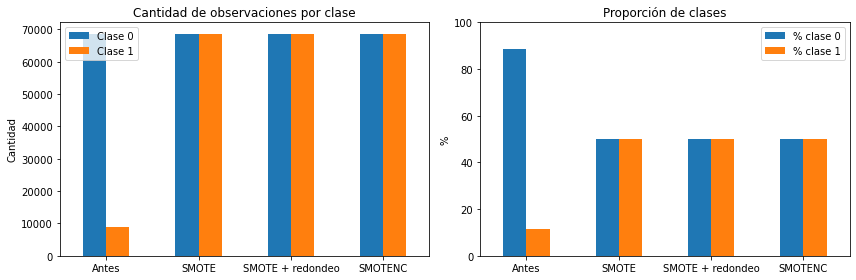

In [116]:
conteos = comparacion_balance[["Clase 0","Clase 1"]]

fig, ax = plt.subplots(1,2,figsize=(12,4))

conteos.plot(kind="bar", ax=ax[0])
ax[0].set_title("Cantidad de observaciones por clase")
ax[0].set_ylabel("Cantidad")
ax[0].tick_params(axis="x", rotation=0)

porcentajes = comparacion_balance[["% clase 0","% clase 1"]]
porcentajes.plot(kind="bar", ax=ax[1])
ax[1].set_title("Proporción de clases")
ax[1].set_ylabel("%")
ax[1].set_ylim(0,100)
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

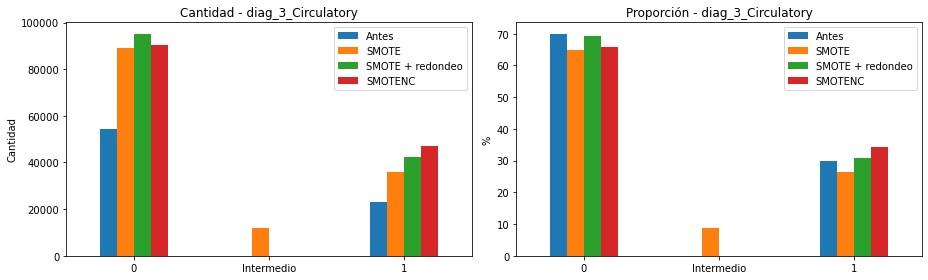

,Antes,SMOTE,SMOTE + redondeo,SMOTENC
0,54429,89265,95289,90506
Intermedio,0,12081,0,0
1,23253,36122,42179,46962


In [117]:
col = "diag_3_Circulatory"

def clasificar_valor(x):
    if np.isclose(x, 0): return "0"
    if np.isclose(x, 1): return "1"
    return "Intermedio"

antes = X_train_original[col].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)
smote = X_smote[col].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)
smote_round = X_smote_round[col].apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)

smotenc_circ = (X_smotenc["diag_3"] == "Circulatory").astype(int)
smotenc_comp = smotenc_circ.apply(clasificar_valor).value_counts().reindex(["0","Intermedio","1"], fill_value=0)

comparacion_diag3 = pd.DataFrame({
    "Antes": antes,
    "SMOTE": smote,
    "SMOTE + redondeo": smote_round,
    "SMOTENC": smotenc_comp
})

fig, ax = plt.subplots(1,2,figsize=(13,4))

comparacion_diag3.plot(kind="bar", ax=ax[0])
ax[0].set_title("Cantidad - diag_3_Circulatory")
ax[0].set_ylabel("Cantidad")
ax[0].tick_params(axis="x", rotation=0)

(comparacion_diag3/comparacion_diag3.sum()*100).plot(kind="bar", ax=ax[1])
ax[1].set_title("Proporción - diag_3_Circulatory")
ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

comparacion_diag3

SMOTENC logró equilibrar completamente las clases, pasando de 68.734 observaciones de clase 0 y 8.948 de clase 1 a 68.734 observaciones en cada clase.

A diferencia del SMOTE convencional aplicado sobre variables One-Hot, las nuevas observaciones mantienen categorías válidas sin necesidad de realizar un redondeo posterior. Esto lo convierte en una alternativa metodológicamente más adecuada para un conjunto de datos con variables numéricas y categóricas.

En `diag_3_Circulatory`, la proporción original de la categoría positiva era aproximadamente 29,9%. Luego del balanceo, SMOTE + redondeo la mantiene cercana al valor original (30,7%), mientras que SMOTENC aumenta su representación hasta aproximadamente 34,2%.

##### 8.1.2 Weighted Random Sampling

Finalmente se evalúa una estrategia de muestreo ponderado. En **Weighted Random Sampling**, cada observación recibe una probabilidad de selección inversamente relacionada con la frecuencia de su clase.

De esta manera, las observaciones de la clase minoritaria tienen mayor probabilidad de ser seleccionadas. El muestreo se realiza con reemplazo y mantiene el mismo número total de observaciones que el conjunto de entrenamiento original.

In [118]:
from sklearn.utils.class_weight import compute_sample_weight

pesos = compute_sample_weight(class_weight="balanced", y=y_train_original)
rng = np.random.default_rng(42)

indices = rng.choice(
    np.arange(len(y_train_original)),
    size=len(y_train_original),
    replace=True,
    p=pesos/pesos.sum()
)

X_weighted = X_train_original.iloc[indices].reset_index(drop=True)
y_weighted = y_train_original.iloc[indices].reset_index(drop=True)

print("Original:")
print(y_train_original.value_counts())

print("\nWeighted Random Sampling:")
print(y_weighted.value_counts())

print("\nProporciones:")
print(y_weighted.value_counts(normalize=True).round(4))

Original:
0    68734
1     8948
Name: readmitted_30, dtype: int64

Weighted Random Sampling:
0    39150
1    38532
Name: readmitted_30, dtype: int64

Proporciones:
0    0.504
1    0.496
Name: readmitted_30, dtype: float64


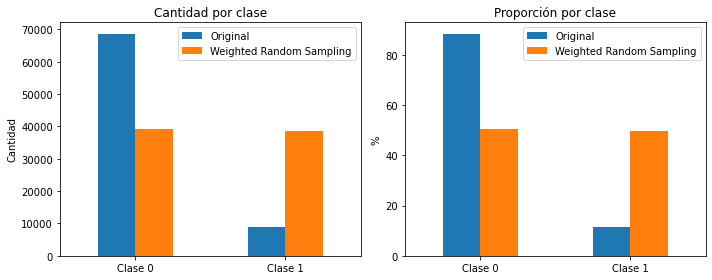

In [119]:
comparacion_weighted = pd.DataFrame({
    "Original": y_train_original.value_counts().sort_index(),
    "Weighted Random Sampling": y_weighted.value_counts().sort_index()
})

fig, ax = plt.subplots(1,2,figsize=(10,4))
comparacion_weighted.plot(kind="bar", ax=ax[0]); ax[0].set_title("Cantidad por clase"); ax[0].set_ylabel("Cantidad"); ax[0].set_xticklabels(["Clase 0","Clase 1"], rotation=0)
(comparacion_weighted/comparacion_weighted.sum()*100).plot(kind="bar", ax=ax[1]); ax[1].set_title("Proporción por clase"); ax[1].set_ylabel("%"); ax[1].set_xticklabels(["Clase 0","Clase 1"], rotation=0)
plt.tight_layout(); plt.show()

Weighted Random Sampling produjo una distribución prácticamente equilibrada, con 50,4% de observaciones de clase 0 y 49,6% de clase 1, manteniendo un total de 77.682 observaciones.

En este muestreo particular, la clase 0 pasó de 68.734 a 39.150 observaciones seleccionadas y la clase 1 de 8.948 a 38.532. Esto no implica eliminar definitivamente observaciones del conjunto original: al realizarse un muestreo con reemplazo, algunas observaciones pueden seleccionarse varias veces y otras pueden no aparecer en una determinada muestra.

Por este motivo, Weighted Random Sampling resulta especialmente útil como estrategia aplicada durante el entrenamiento de un modelo, más que como una transformación permanente del dataset.

##### 8.1.3 Decisión final sobre el desbalance

El undersampling implica una pérdida importante de información de la clase mayoritaria, mientras que las técnicas de oversampling sintético requieren generar una gran cantidad de observaciones artificiales para alcanzar un balance 1:1.

Como estrategia preferida se propone **Weighted Random Sampling** durante el entrenamiento del modelo. Este método aumenta la probabilidad de seleccionar observaciones de la clase minoritaria sin modificar permanentemente el dataset ni generar nuevos registros sintéticos.

Dado que este trabajo se centra en la preparación y análisis de los datos y no incluye el entrenamiento de modelos, el conjunto de entrenamiento se mantiene con su distribución original.

### 9. Selección de features

Siguiendo los mecanismos vistos en clase, se utilizan distintos métodos de selección según el tipo de variable:

- **ANOVA F** para evaluar la relación entre las variables numéricas y la variable objetivo categórica.
- **Chi-cuadrado** para evaluar las variables categóricas previamente codificadas.
- **Información Mutua (MI)** como medida adicional de dependencia entre cada feature y la variable objetivo.

Los resultados se complementarán con el análisis de asociaciones entre predictores realizado previamente, con el objetivo de considerar tanto la relevancia respecto de la variable objetivo como la posible redundancia entre features.

In [120]:
# Separamos features para los distintos métodos de selección
num_features_fs = variables_numericas_raw + ["age"]
cat_features_fs = [col for col in X_train.columns if col not in num_features_fs]

X_train_num_fs = X_train[num_features_fs].copy()
X_train_cat_fs = X_train[cat_features_fs].copy()

print("Features numéricas/ordinales:", len(num_features_fs))
print("Features categóricas codificadas:", len(cat_features_fs))
print("Total:", len(num_features_fs) + len(cat_features_fs))
print("Columnas X_train:", X_train.shape[1])

Features numéricas/ordinales: 9
Features categóricas codificadas: 169
Total: 178
Columnas X_train: 178


#### 9.1 ANOVA

In [121]:
from sklearn.feature_selection import SelectKBest, f_classif

selector_anova = SelectKBest(score_func=f_classif, k="all")
selector_anova.fit(X_train_num_fs, y_train)

anova_result = pd.DataFrame({
    "F_score": selector_anova.scores_,
    "p_value": selector_anova.pvalues_
}, index=num_features_fs).sort_values("F_score", ascending=False)

anova_result.round(4)

,F_score,p_value
number_inpatient,2206.3304,0.0000
number_emergency,265.5202,0.0000
number_diagnoses,225.5006,0.0000
time_in_hospital,153.7597,0.0000
num_medications,139.1981,0.0000
num_lab_procedures,42.1602,0.0000
age,40.1506,0.0000
number_outpatient,23.3797,0.0000
num_procedures,6.9432,0.0084


Interpretación:
`number_inpatient` presenta el mayor F-score (2206,33), por encima del resto de las variables, indicando que el número de internaciones previas es la variable numérica con mayor poder discriminante respecto de la readmisión antes de 30 días.

Le siguen `number_emergency` y `number_diagnoses`, aunque con valores menores. `age` y `num_procedures` presentan los F-scores más bajos dentro de este grupo.

Debido al gran tamaño de la muestra, la significancia estadística por sí sola no se utiliza como criterio de selección; se considera también la magnitud relativa del F-score y los resultados obtenidos mediante otros métodos de selección.

#### 9.2 Chi cuadrado

In [122]:
from sklearn.feature_selection import chi2

selector_chi2 = SelectKBest(score_func=chi2, k="all")
selector_chi2.fit(X_train_cat_fs, y_train)

chi2_result = pd.DataFrame({
    "chi2_score": selector_chi2.scores_,
    "p_value": selector_chi2.pvalues_
}, index=cat_features_fs).sort_values("chi2_score", ascending=False)

chi2_result.head(20).round(4)

,chi2_score,p_value
discharge_disposition_id_22,413.5869,0.0
discharge_disposition_id_1,203.1091,0.0
discharge_disposition_id_3,108.5283,0.0
discharge_disposition_id_5,94.6236,0.0
insulin_Down,73.0859,0.0
discharge_disposition_id_28,72.8308,0.0
discharge_disposition_id_15,62.3932,0.0
insulin_No,45.9735,0.0
metformin_Steady,44.3439,0.0
medical_specialty_Cardiology,43.8747,0.0


#### 9.3 Información Mutua

In [123]:
from sklearn.feature_selection import mutual_info_classif

discrete_mask = [col in cat_features_fs for col in X_train.columns]

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

mi_result = pd.DataFrame({
    "MI_score": mi_scores
}, index=X_train.columns).sort_values("MI_score", ascending=False)

mi_result.head(20).round(4)

,MI_score
number_inpatient,0.0105
number_diagnoses,0.0040
time_in_hospital,0.0037
discharge_disposition_id_1,0.0032
age,0.0032
num_procedures,0.0024
number_emergency,0.0024
discharge_disposition_id_22,0.0021
num_medications,0.0009
discharge_disposition_id_3,0.0008


Interpretación: Los valores de Información Mutua son bajos en términos absolutos, lo que indica que ninguna variable individual contiene una gran cantidad de información sobre `readmitted_30`. Los resultados sugieren que la readmisión temprana depende probablemente de la combinación de múltiples características y no de un único predictor dominante.

#### 9.4 Comparación de métodos

In [124]:
from sklearn.preprocessing import MinMaxScaler

comparacion = pd.DataFrame(index=X_train.columns)

comparacion["ANOVA_F"] = anova_result["F_score"]
comparacion["Ranking_ANOVA"] = comparacion["ANOVA_F"].rank(ascending=False, method="min")

comparacion["Chi2"] = chi2_result["chi2_score"]
comparacion["Ranking_Chi2"] = comparacion["Chi2"].rank(ascending=False, method="min")

comparacion["MI"] = mi_result["MI_score"]
comparacion["Ranking_MI"] = comparacion["MI"].rank(ascending=False, method="min")

comparacion.sort_values("MI", ascending=False).head(20).round(4)

,ANOVA_F,Ranking_ANOVA,Chi2,Ranking_Chi2,MI,Ranking_MI
number_inpatient,2206.3304,1.0,NaN,NaN,0.0105,1.0
number_diagnoses,225.5006,3.0,NaN,NaN,0.0040,2.0
time_in_hospital,153.7597,4.0,NaN,NaN,0.0037,3.0
discharge_disposition_id_1,NaN,NaN,203.1091,2.0,0.0032,4.0
age,40.1506,7.0,NaN,NaN,0.0032,5.0
num_procedures,6.9432,9.0,NaN,NaN,0.0024,6.0
number_emergency,265.5202,2.0,NaN,NaN,0.0024,7.0
discharge_disposition_id_22,NaN,NaN,413.5869,1.0,0.0021,8.0
num_medications,139.1981,5.0,NaN,NaN,0.0009,9.0
discharge_disposition_id_3,NaN,NaN,108.5283,3.0,0.0008,10.0


In [126]:
comparacion_norm = pd.DataFrame(index=comparacion.index)

for origen, destino in [("ANOVA_F","ANOVA"),("Chi2","Chi2"),("MI","MI")]:
    mask = comparacion[origen].notna()
    scaler = MinMaxScaler()
    comparacion_norm.loc[mask, destino] = scaler.fit_transform(comparacion.loc[mask, [origen]]).ravel()

comparacion_norm.head()

,ANOVA,Chi2,MI
gender,NaN,0.000206,0.000097
age,0.015098,NaN,0.309416
time_in_hospital,0.066753,NaN,0.351111
num_lab_procedures,0.016012,NaN,0.000000
num_procedures,0.000000,NaN,0.229029


In [127]:
# Identifico a qué variable original pertenece cada columna
nominales_ordenadas = sorted(variables_nominales, key=len, reverse=True)

def variable_original(col):
    for var in nominales_ordenadas:
        if col.startswith(var + "_"):
            return var
    return col

comparacion_var = comparacion_norm[["ANOVA","Chi2","MI"]].copy()
comparacion_var["variable_original"] = [variable_original(col) for col in comparacion_var.index]

# Agrupo las categorías OHE y tomo el mayor score de cada variable
ranking_variables = comparacion_var.groupby("variable_original")[["ANOVA","Chi2","MI"]].max()

ranking_variables["score_consenso"] = ranking_variables[["ANOVA","Chi2","MI"]].mean(axis=1, skipna=True)

ranking_variables.sort_values("score_consenso").round(4)

,ANOVA,Chi2,MI,score_consenso
variable_original,,,,
metformin-rosiglitazone,NaN,0.0000,0.0000,0.0000
glipizide-metformin,NaN,0.0002,0.0000,0.0001
gender,NaN,0.0002,0.0001,0.0002
metformin-pioglitazone,NaN,0.0003,0.0002,0.0002
acetohexamide,NaN,0.0003,0.0002,0.0002
tolazamide,NaN,0.0003,0.0002,0.0002
glimepiride-pioglitazone,NaN,0.0003,0.0002,0.0002
troglitazone,NaN,0.0009,0.0005,0.0007
glyburide-metformin,NaN,0.0019,0.0009,0.0014


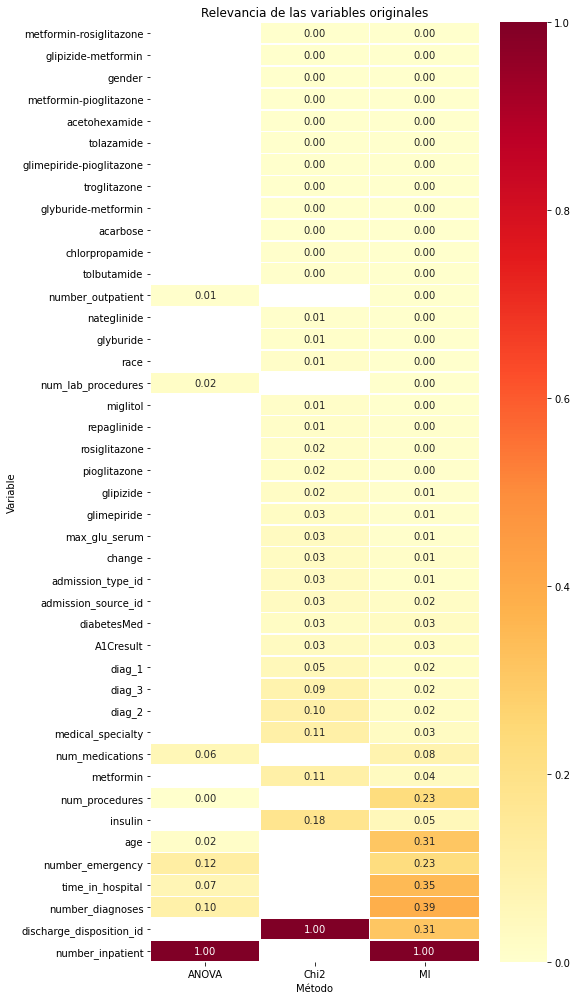

In [128]:
ranking_ordenado = ranking_variables.sort_values("score_consenso")

plt.figure(figsize=(8,14))
sns.heatmap(ranking_ordenado[["ANOVA","Chi2","MI"]],
            annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=.5)

plt.title("Relevancia de las variables originales")
plt.xlabel("Método")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

Al integrar los resultados de ANOVA, Chi-cuadrado e Información Mutua, se agruparon nuevamente las variables provenientes del One-Hot Encoding según su variable original.

Los métodos muestran un grupo de variables con relevancia prácticamente nula respecto de `readmitted_30`. Se decidió eliminar únicamente aquellas cuyo score de consenso normalizado fue menor a 0,001:

- `metformin-rosiglitazone`
- `glipizide-metformin`
- `gender`
- `metformin-pioglitazone`
- `acetohexamide`
- `tolazamide`
- `glimepiride-pioglitazone`
- `troglitazone`

La selección se realiza de forma conservadora con el objetivo de reducir variables con aporte prácticamente nulo sin perder información potencialmente útil.

In [129]:
variables_eliminar = [
    "metformin-rosiglitazone",
    "glipizide-metformin",
    "gender",
    "metformin-pioglitazone",
    "acetohexamide",
    "tolazamide",
    "glimepiride-pioglitazone",
    "troglitazone"
]

In [130]:
cols_eliminar = [c for c in X_train.columns if c in variables_eliminar or any(c.startswith(v+"_") for v in variables_eliminar)]

X_train_fs = X_train.drop(columns=cols_eliminar)
X_test_fs = X_test.drop(columns=cols_eliminar)

print("Antes:", X_train.shape[1])
print("Después:", X_train_fs.shape[1])
print("Columnas eliminadas:", len(cols_eliminar))

Antes: 178
Después: 163
Columnas eliminadas: 15


### 10. PCA

Se implementa Análisis de Componentes Principales (PCA) como técnica de extracción de features.

En el análisis previo de este dataset no se observaron asociaciones fuertes entre los predictores, por lo que se evaluará si PCA permite una reducción sustancial de dimensionalidad o si la varianza permanece distribuida entre un número elevado de componentes.

In [131]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()
X_train_pca_scaled = scaler_pca.fit_transform(X_train_fs)
X_test_pca_scaled = scaler_pca.transform(X_test_fs)

pca = PCA()
X_train_pca = pca.fit_transform(X_train_pca_scaled)

var_acum = np.cumsum(pca.explained_variance_ratio_)

for nivel in [0.80, 0.90, 0.95]:
    n = np.argmax(var_acum >= nivel) + 1
    print(f"{int(nivel*100)}% de varianza: {n} componentes")

80% de varianza: 96 componentes
90% de varianza: 113 componentes
95% de varianza: 123 componentes


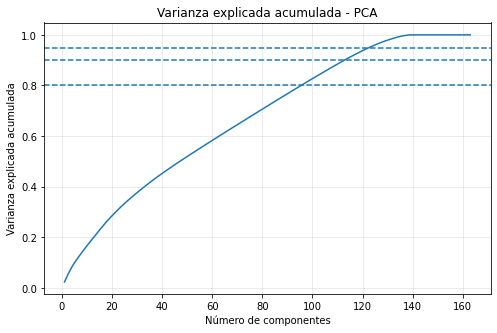

In [132]:
plt.figure(figsize=(8,5))
plt.plot(range(1,len(var_acum)+1),var_acum)
plt.axhline(0.80,ls="--")
plt.axhline(0.90,ls="--")
plt.axhline(0.95,ls="--")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada - PCA")
plt.grid(alpha=.3)
plt.show()

In [133]:
X_test_pca = pca.transform(X_test_pca_scaled)

Interpretación: Los resultados muestran que PCA no permite una reducción drástica de la dimensionalidad sin perder una proporción importante de la varianza:

- Para conservar el 80% de la varianza se requieren 96 componentes.
- Para conservar el 90% se requieren 113 componentes.
- Para conservar el 95% se requieren 123 componentes.

El resultado es consistente con el análisis previo de asociaciones entre predictores, donde no se observaron correlaciones suficientemente fuertes como para evidenciar una alta redundancia entre variables.

**Ventajas**
- Permite reducir la cantidad de dimensiones conservando una proporción controlada de la varianza.
- Puede reducir el costo computacional de modelos posteriores.

**Desventajas**
- En este dataset se necesita conservar un número elevado de componentes para retener una proporción importante de la varianza, por lo que la reducción es limitada.
- La presencia de muchas variables categóricas codificadas mediante One-Hot Encoding hace que las componentes resultantes sean todavía más difíciles de interpretar.

Por estas razones, para este problema se considera más conveniente conservar el conjunto obtenido mediante selección de features y utilizar PCA principalmente como herramienta de evaluación de reducción dimensional, sin adoptarlo como transformación final.

### 11. Conclusiones

El análisis permitió preparar el dataset de pacientes con diabetes para un posible problema de clasificación binaria orientado a predecir la readmisión hospitalaria dentro de los 30 días posteriores al alta.

Uno de los principales desafíos del dataset fue la combinación de valores faltantes, alta cardinalidad en algunas variables categóricas, múltiples encuentros correspondientes a un mismo paciente y un marcado desbalance de la variable objetivo. Estas características requirieron tomar decisiones específicas durante la preparación de los datos.

Para evitar fuga de información, la separación entre train y test se realizó agrupando por paciente y conservando aproximadamente la proporción de la variable objetivo. Los valores faltantes fueron tratados según su posible mecanismo de ausencia, diferenciando faltantes administrativos, estructurales y variables con porcentajes de ausencia demasiado elevados. Los outliers detectados en variables de conteo fueron conservados, ya que representan valores clínicamente plausibles y no errores evidentes.

Las variables diagnósticas ICD-9 fueron agrupadas en categorías clínicas generales para reducir su cardinalidad. Las variables categóricas fueron codificadas y las variables numéricas se escalaron mediante `RobustScaler`, debido a la presencia de distribuciones asimétricas y valores extremos.

El problema presenta un importante desbalance de clases, con aproximadamente un 11% de readmisiones tempranas. Se evaluaron distintas estrategias de balanceo y se consideró que `Weighted Random Sampling` sería una alternativa adecuada durante el entrenamiento, ya que permite aumentar la representación de la clase minoritaria sin generar observaciones sintéticas ni modificar permanentemente el conjunto de datos.

La selección de features mediante ANOVA, Chi-cuadrado e Información Mutua mostró que ninguna variable individual posee una relación especialmente fuerte con la readmisión temprana. `number_inpatient` fue la variable que mostró mayor relevancia de manera más consistente, seguida por variables relacionadas con la cantidad de diagnósticos, duración de la internación, utilización previa del sistema de salud y disposición al alta. Esto sugiere que la readmisión probablemente depende de la interacción de múltiples características y no de un único predictor.

La selección conservadora de features permitió reducir el conjunto de 178 a 163 variables codificadas, eliminando principalmente variables con aporte prácticamente nulo. Por otro lado, no se encontraron asociaciones suficientemente fuertes entre predictores como para justificar una eliminación adicional por redundancia.

Finalmente, PCA mostró una capacidad limitada para reducir la dimensionalidad: se requieren 96 componentes para conservar el 80% de la varianza, 113 para el 90% y 123 para el 95%. Esto indica que la información se encuentra distribuida entre numerosas dimensiones. Además, el uso de PCA reduciría la interpretabilidad clínica de las variables.

Por este motivo, se considera más conveniente conservar como conjunto final el obtenido mediante selección de features, sin aplicar PCA como transformación definitiva. El dataset resultante queda preparado para una futura etapa de entrenamiento y evaluación de modelos de clasificación.